# AI-Based Pediatric Appendicitis Diagnosis & Severity Prediction
## Development notebook (cleaned)

This is the cleaned version of the original Kaggle development notebook. Duplicate,
debugging and broken cells were removed, and it now runs top to bottom without errors.

**Sections**
1. Setup
2. Clinical data: loading, cleaning, target, EDA
3. Clinical preprocessing (90 features)
4. Clinical machine-learning models
5. Ultrasound images: linking, checks, patient-level split
6. ResNet18 image model and feature extraction
7. Ultrasound-only models
8. Multimodal fusion (clinical + ultrasound)
9. Explainability: SHAP and Grad-CAM
10. Final model (maximum accuracy) + app export
11. Validation: does ultrasound add value? (5×5 cross-validation)
12. Conclusion

Three-class target: **0 = No appendicitis, 1 = Uncomplicated, 2 = Complicated**.

> Results in this notebook come from single train/test splits and were used during development.
> Sections 1–9 are single-split development experiments. Section 10 builds the final model and
> Section 11 is the validated comparison (same patients, repeated cross-validation) used in the paper.

# 1. Setup

In [1]:
import os, re, glob, random, copy, time, hashlib, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import models, transforms
from PIL import Image

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2      # Windows notebooks cannot use worker processes
CLASS_NAMES = ["No appendicitis", "Uncomplicated appendicitis", "Complicated appendicitis"]

# ---------------- Paths (Kaggle or local laptop) ----------------
def find_one(pattern, what):
    hits = sorted(glob.glob(pattern, recursive=True))
    if not hits:
        raise FileNotFoundError(f"Could not find {what} ({pattern}). Attach it via 'Add Input'.")
    return hits[0]

if os.path.exists("/kaggle/input"):
    DATA_XLSX = find_one("/kaggle/input/**/app_data.xlsx", "app_data.xlsx")
    IMG_DIR = os.path.dirname(find_one("/kaggle/input/**/US_Pictures/**/*.bmp", "US_Pictures images"))
    WEIGHTS = find_one("/kaggle/input/**/resnet18*.pth", "ResNet18 weights")
    RESULTS = "/kaggle/working/results"
else:
    PROJECT = r"C:\Users\MUSAIB\Desktop\Appendixai"
    DATA_XLSX = os.path.join(PROJECT, "Data", "clinical", "app_data.xlsx")
    IMG_DIR = os.path.join(PROJECT, "Data", "ultrasound", "US_Pictures")
    WEIGHTS = os.path.join(PROJECT, "models", "resnet18-f37072fd (1).pth")
    RESULTS = os.path.join(PROJECT, "results")
os.makedirs(RESULTS, exist_ok=True)

print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Data   :", DATA_XLSX)
print("Images :", IMG_DIR)
print("Weights:", WEIGHTS)


PyTorch: 2.12.1+cu126 | CUDA: True | NVIDIA GeForce RTX 3050 Ti Laptop GPU
Data   : C:\Users\MUSAIB\Desktop\Appendixai\Data\clinical\app_data.xlsx
Images : C:\Users\MUSAIB\Desktop\Appendixai\Data\ultrasound\US_Pictures
Weights: C:\Users\MUSAIB\Desktop\Appendixai\models\resnet18-f37072fd (1).pth


# 2. Clinical data
## 2.1 Load and inspect

In [2]:
df_raw = pd.read_excel(DATA_XLSX)
print("Shape:", df_raw.shape)
display(df_raw.head())


Shape: (782, 58)


,Age,BMI,Sex,Height,Weight,Length_of_Stay,Management,Severity,Diagnosis_Presumptive,Diagnosis,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_on_US,Appendix_Diameter,Migratory_Pain,Lower_Right_Abd_Pain,Contralateral_Rebound_Tenderness,Coughing_Pain,Nausea,Loss_of_Appetite,Body_Temperature,WBC_Count,Neutrophil_Percentage,Segmented_Neutrophils,Neutrophilia,RBC_Count,Hemoglobin,RDW,Thrombocyte_Count,Ketones_in_Urine,RBC_in_Urine,WBC_in_Urine,CRP,Dysuria,Stool,Peritonitis,Psoas_Sign,Ipsilateral_Rebound_Tenderness,US_Performed,US_Number,Free_Fluids,Appendix_Wall_Layers,Target_Sign,Appendicolith,Perfusion,Perforation,Surrounding_Tissue_Reaction,Appendicular_Abscess,Abscess_Location,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings
0,12.68,16.9,female,148.0,37.0,3.0,conservative,uncomplicated,appendicitis,appendicitis,4.0,3.0,yes,7.1,no,yes,yes,no,no,yes,37.0,7.7,68.2,NaN,no,5.27,14.8,12.2,254.0,++,+,no,0.0,no,normal,no,yes,no,yes,882.0,no,intact,NaN,suspected,NaN,no,yes,no,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,14.10,31.9,male,147.0,69.5,2.0,conservative,uncomplicated,appendicitis,no appendicitis,5.0,4.0,no,NaN,yes,yes,yes,no,no,yes,36.9,8.1,64.8,NaN,no,5.26,15.7,12.7,151.0,no,no,no,3.0,yes,normal,no,yes,no,yes,883.0,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN
2,14.14,23.3,female,163.0,62.0,4.0,conservative,uncomplicated,appendicitis,no appendicitis,5.0,3.0,no,NaN,no,yes,yes,no,no,no,36.6,13.2,74.8,NaN,no,3.98,11.4,12.2,300.0,no,no,no,3.0,no,constipation,no,yes,no,yes,884.0,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,yes,NaN
3,16.37,20.6,female,165.0,56.0,3.0,conservative,uncomplicated,appendicitis,no appendicitis,7.0,6.0,no,NaN,yes,yes,no,no,yes,yes,36.0,11.4,63.0,NaN,no,4.64,13.6,13.2,258.0,no,no,no,0.0,yes,normal,no,yes,no,yes,886.0,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN
4,11.08,16.9,female,163.0,45.0,3.0,conservative,uncomplicated,appendicitis,appendicitis,5.0,6.0,yes,7.0,no,yes,yes,yes,yes,yes,36.9,8.1,44.0,NaN,no,4.44,12.6,13.6,311.0,no,no,no,0.0,no,constipation,no,yes,no,yes,887.0,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 58 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Age                               781 non-null    float64
 1   BMI                               755 non-null    float64
 2   Sex                               780 non-null    str    
 3   Height                            756 non-null    float64
 4   Weight                            779 non-null    float64
 5   Length_of_Stay                    778 non-null    float64
 6   Management                        781 non-null    str    
 7   Severity                          781 non-null    str    
 8   Diagnosis_Presumptive             780 non-null    str    
 9   Diagnosis                         780 non-null    str    
 10  Alvarado_Score                    730 non-null    float64
 11  Paedriatic_Appendicitis_Score     730 non-null    float64
 12  Appendix_on_US     

In [4]:
print("Diagnosis values:", df_raw["Diagnosis"].unique())
print("Severity values :", df_raw["Severity"].unique())
print("\nRows with missing Diagnosis or Severity:")
display(df_raw.loc[df_raw["Diagnosis"].isna() | df_raw["Severity"].isna(),
                   ["Diagnosis", "Severity", "Management"]])


Diagnosis values: <ArrowStringArray>
['appendicitis', 'no appendicitis', nan]
Length: 3, dtype: str
Severity values : <ArrowStringArray>
['uncomplicated', nan, 'complicated']
Length: 3, dtype: str

Rows with missing Diagnosis or Severity:


,Diagnosis,Severity,Management
428,NaN,NaN,NaN
535,NaN,uncomplicated,secondary surgical


## 2.2 Cleaning
- Rows 428 and 535 have no Diagnosis/Severity, so they are dropped.
- One missing `Sex` value (row 625) is set to the most common value, "male".

In [5]:
df_full = df_raw.drop(index=[428, 535]).copy()
print("Sex mode:", df_full["Sex"].mode()[0], "| missing Sex rows:", df_full.index[df_full["Sex"].isna()].tolist())
df_full.loc[625, "Sex"] = "male"
print("Shape after dropping rows:", df_full.shape)


Sex mode: male | missing Sex rows: [625]
Shape after dropping rows: (780, 58)


,Missing Count,Missing %
Abscess_Location,767,98.333333
Gynecological_Findings,754,96.666667
Conglomerate_of_Bowel_Loops,737,94.487179
Segmented_Neutrophils,726,93.076923
Ileus,720,92.307692
Perfusion,717,91.923077
Enteritis,714,91.538462
Appendicolith,711,91.153846
Coprostasis,709,90.897436
Perforation,699,89.615385


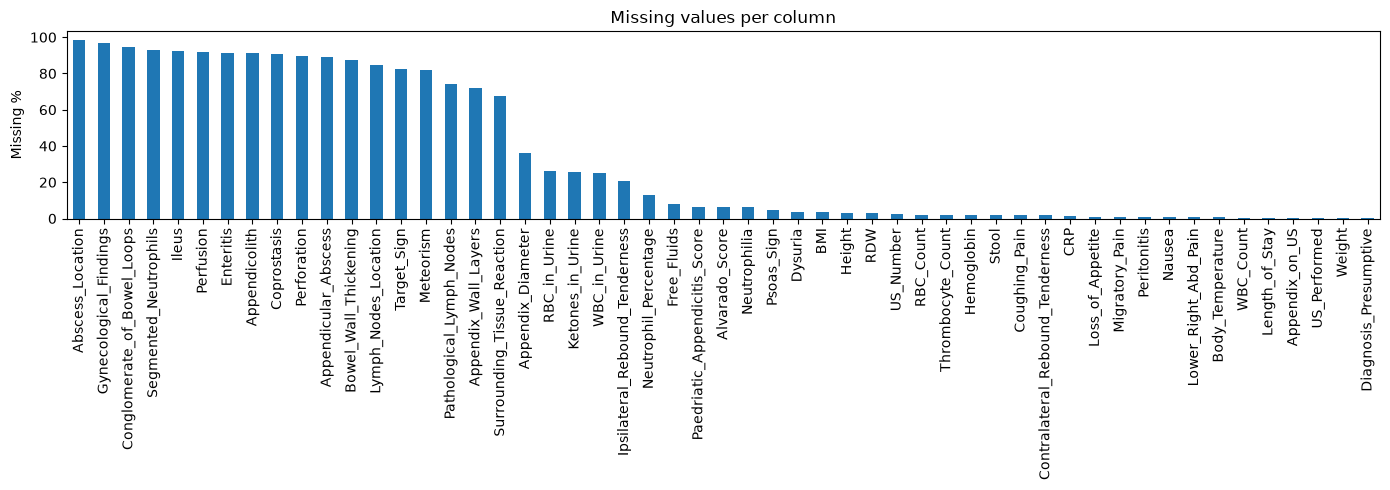

In [6]:
missing = pd.DataFrame({
    "Missing Count": df_full.isnull().sum(),
    "Missing %": df_full.isnull().mean() * 100,
})
missing = missing[missing["Missing Count"] > 0].sort_values("Missing %", ascending=False)
display(missing)

plt.figure(figsize=(14, 5))
missing["Missing %"].plot(kind="bar")
plt.ylabel("Missing %")
plt.title("Missing values per column")
plt.tight_layout()
plt.show()


In [7]:
print("Target-related columns:")
display(df_full[["Diagnosis", "Severity", "Management"]].value_counts(dropna=False))


Target-related columns:


Diagnosis        Severity       Management               
no appendicitis  uncomplicated  conservative                 313
appendicitis     uncomplicated  conservative                 170
                                primary surgical             154
                 complicated    primary surgical             114
                 uncomplicated  secondary surgical            21
                 complicated    secondary surgical             4
no appendicitis  uncomplicated  secondary surgical             1
                 complicated    primary surgical               1
                 uncomplicated  primary surgical               1
                                simultaneous appendectomy      1
Name: count, dtype: int64

## 2.3 Target variable
- 0: no appendicitis
- 1: appendicitis + uncomplicated
- 2: appendicitis + complicated

Note: in the raw data almost all *no appendicitis* patients have `Severity = uncomplicated`,
so `Severity` alone is not a valid severity label; the target must combine both columns.

Rows with undefined target: 0


,Class,Patients,%
0,No appendicitis,317,40.64
1,Uncomplicated appendicitis,345,44.23
2,Complicated appendicitis,118,15.13


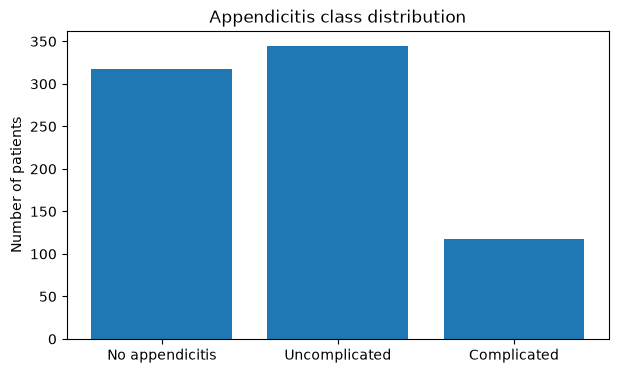

In [8]:
def create_target(row):
    if row["Diagnosis"] == "no appendicitis":
        return 0
    if row["Diagnosis"] == "appendicitis" and row["Severity"] == "uncomplicated":
        return 1
    if row["Diagnosis"] == "appendicitis" and row["Severity"] == "complicated":
        return 2
    return np.nan

df_full["Target"] = df_full.apply(create_target, axis=1)
print("Rows with undefined target:", df_full["Target"].isna().sum())
df_full = df_full.dropna(subset=["Target"]).copy()
df_full["Target"] = df_full["Target"].astype(int)

counts = df_full["Target"].value_counts().sort_index()
display(pd.DataFrame({"Class": CLASS_NAMES, "Patients": counts.values,
                      "%": (counts.values / counts.sum() * 100).round(2)}))

plt.figure(figsize=(7, 4))
plt.bar(["No appendicitis", "Uncomplicated", "Complicated"], counts.values)
plt.title("Appendicitis class distribution")
plt.ylabel("Number of patients")
plt.show()


## 2.4 Feature removal
- **High missingness / limited usefulness**: 12 columns
- **Leakage / post-diagnosis information**: Length_of_Stay, Management, Diagnosis_Presumptive, Perforation
- **Scores derived from the same variables**: Alvarado_Score, Paedriatic_Appendicitis_Score
- **Identifier**: US_Number (kept in `df_full` for linking images later)

In [9]:
drop_cols = [
    "Abscess_Location", "Gynecological_Findings", "Conglomerate_of_Bowel_Loops",
    "Segmented_Neutrophils", "Ileus", "Enteritis", "Coprostasis", "Lymph_Nodes_Location",
    "Target_Sign", "Meteorism", "Pathological_Lymph_Nodes", "Appendicular_Abscess",
    "Length_of_Stay", "Management", "Diagnosis_Presumptive", "Perforation",
    "Alvarado_Score", "Paedriatic_Appendicitis_Score", "US_Number",
]
df = df_full.drop(columns=drop_cols + ["Severity", "Diagnosis"])
print("Modeling dataframe:", df.shape)
print("Duplicate rows:", df.duplicated().sum())


Modeling dataframe: (780, 38)
Duplicate rows: 0


## 2.5 Exploratory data analysis

In [10]:
num_cols_all = df.drop(columns="Target").select_dtypes(include="number").columns.tolist()
cat_cols_all = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical columns:", len(num_cols_all), num_cols_all)
print("Categorical columns:", len(cat_cols_all), cat_cols_all)


Numerical columns: 13 ['Age', 'BMI', 'Height', 'Weight', 'Appendix_Diameter', 'Body_Temperature', 'WBC_Count', 'Neutrophil_Percentage', 'RBC_Count', 'Hemoglobin', 'RDW', 'Thrombocyte_Count', 'CRP']
Categorical columns: 24 ['Sex', 'Appendix_on_US', 'Migratory_Pain', 'Lower_Right_Abd_Pain', 'Contralateral_Rebound_Tenderness', 'Coughing_Pain', 'Nausea', 'Loss_of_Appetite', 'Neutrophilia', 'Ketones_in_Urine', 'RBC_in_Urine', 'WBC_in_Urine', 'Dysuria', 'Stool', 'Peritonitis', 'Psoas_Sign', 'Ipsilateral_Rebound_Tenderness', 'US_Performed', 'Free_Fluids', 'Appendix_Wall_Layers', 'Appendicolith', 'Perfusion', 'Surrounding_Tissue_Reaction', 'Bowel_Wall_Thickening']


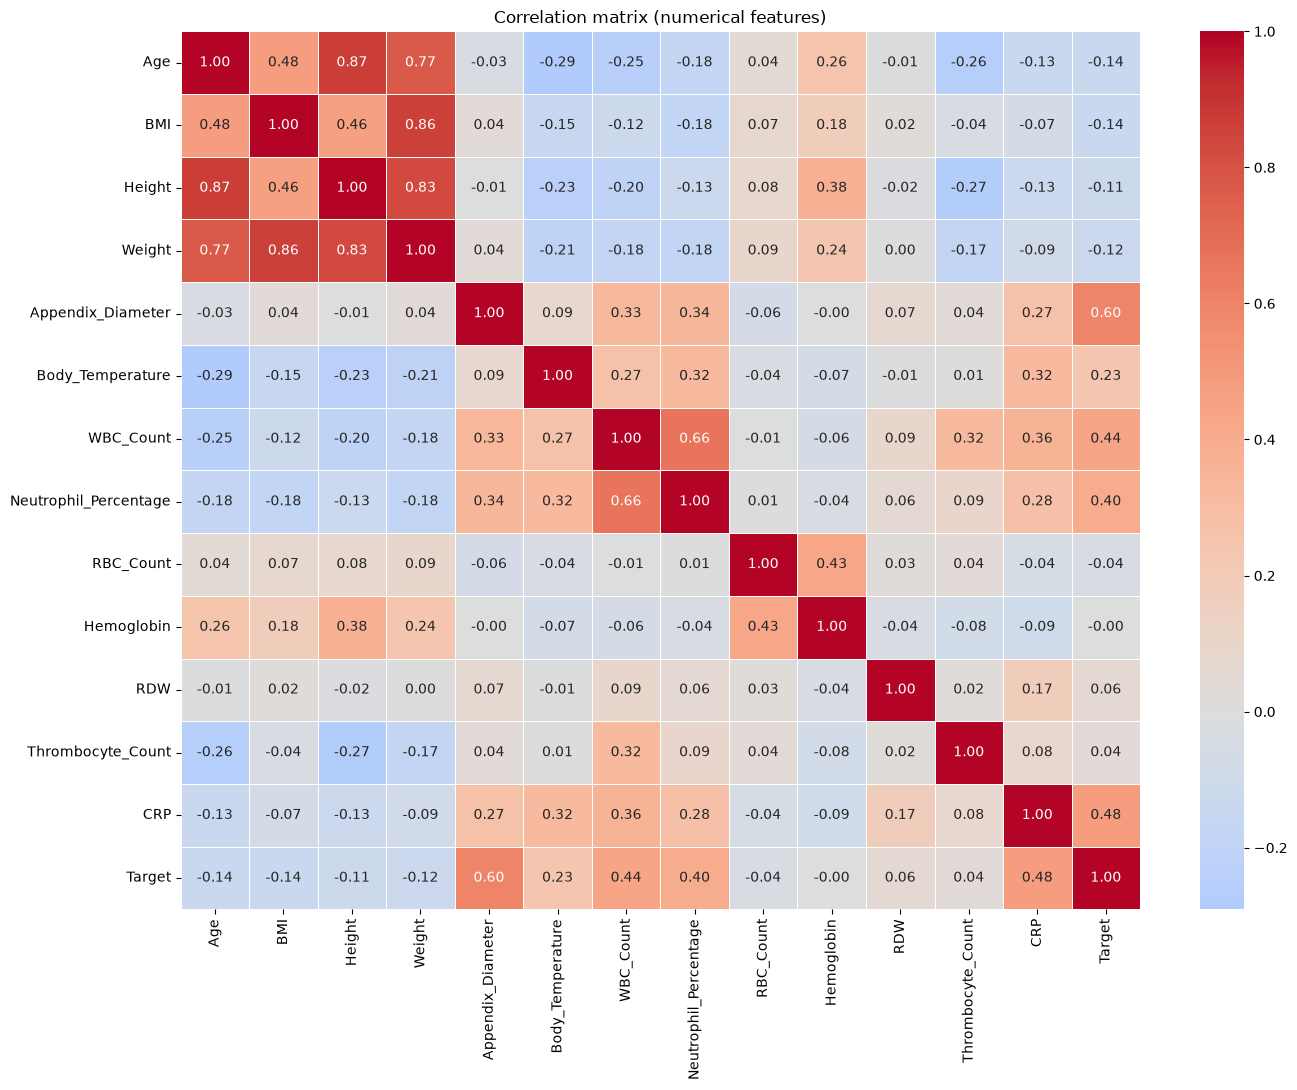

In [11]:
corr_matrix = df[num_cols_all + ["Target"]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation matrix (numerical features)")
plt.tight_layout()
plt.show()


In [12]:
for col in cat_cols_all:
    print(f"\n{'=' * 50}\n{col}")
    print(df[col].value_counts(dropna=False).to_string())



Sex
Sex
male      404
female    376

Appendix_on_US
Appendix_on_US
yes    504
no     273
NaN      3

Migratory_Pain
Migratory_Pain
no     562
yes    211
NaN      7

Lower_Right_Abd_Pain
Lower_Right_Abd_Pain
yes    733
no      41
NaN      6

Contralateral_Rebound_Tenderness
Contralateral_Rebound_Tenderness
no     469
yes    298
NaN     13

Coughing_Pain
Coughing_Pain
no     548
yes    218
NaN     14

Nausea
Nausea
yes    453
no     321
NaN      6

Loss_of_Appetite
Loss_of_Appetite
yes    392
no     380
NaN      8

Neutrophilia
Neutrophilia
no     371
yes    361
NaN     48

Ketones_in_Urine
Ketones_in_Urine
no     332
NaN    198
+++    124
+       77
++      49

RBC_in_Urine
RBC_in_Urine
no     442
NaN    204
+       88
+++     30
++      16

WBC_in_Urine
WBC_in_Urine
no     501
NaN    197
+       51
++      19
+++     12

Dysuria
Dysuria
no     709
yes     44
NaN     27

Stool
Stool
normal                    549
diarrhea                  128
constipation               87
NaN           

# 3. Clinical preprocessing
## 3.1 Stratified train/test split (80/20)

In [13]:
X = df.drop(columns=["Target"])
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train distribution:", y_train.value_counts().sort_index().to_dict())
print("Test distribution :", y_test.value_counts().sort_index().to_dict())


X_train: (624, 37) | X_test: (156, 37)
Train distribution: {0: 254, 1: 276, 2: 94}
Test distribution : {0: 63, 1: 69, 2: 24}


## 3.2 Missing values in the training data
Five ultrasound-report columns are missing for more than 50% of patients and are dropped.

In [14]:
missing_report = pd.DataFrame({
    "Missing_Count": X_train.isna().sum(),
    "Missing_%": X_train.isna().mean() * 100,
})
missing_report = missing_report[missing_report["Missing_Count"] > 0].sort_values("Missing_%", ascending=False)
display(missing_report)

high_missing_cols = ["Perfusion", "Appendicolith", "Bowel_Wall_Thickening",
                     "Appendix_Wall_Layers", "Surrounding_Tissue_Reaction"]
X_train = X_train.drop(columns=high_missing_cols)
X_test = X_test.drop(columns=high_missing_cols)
print("After dropping high-missing columns:", X_train.shape, X_test.shape)


,Missing_Count,Missing_%
Perfusion,572,91.666667
Appendicolith,571,91.506410
Bowel_Wall_Thickening,546,87.500000
Appendix_Wall_Layers,451,72.275641
Surrounding_Tissue_Reaction,420,67.307692
Appendix_Diameter,224,35.897436
RBC_in_Urine,160,25.641026
Ketones_in_Urine,154,24.679487
WBC_in_Urine,154,24.679487
Ipsilateral_Rebound_Tenderness,125,20.032051


After dropping high-missing columns: (624, 32) (156, 32)


## 3.3 Feature behaviour by class (training data only)

In [15]:
numeric_cols = X_train.select_dtypes(include="number").columns
train_analysis = X_train.copy()
train_analysis["Target"] = y_train
print("Mean value of numerical features by class:")
display(train_analysis.groupby("Target")[numeric_cols].mean().T.round(2))


Mean value of numerical features by class:


Target,0,1,2
Age,11.73,11.38,9.75
BMI,19.59,18.55,17.95
Height,149.56,148.49,140.57
Weight,45.46,42.37,37.98
Appendix_Diameter,5.04,8.52,9.39
Body_Temperature,37.22,37.37,37.98
WBC_Count,10.19,13.31,17.45
Neutrophil_Percentage,65.12,74.25,82.60
RBC_Count,4.82,4.81,4.77
Hemoglobin,13.36,13.40,13.39


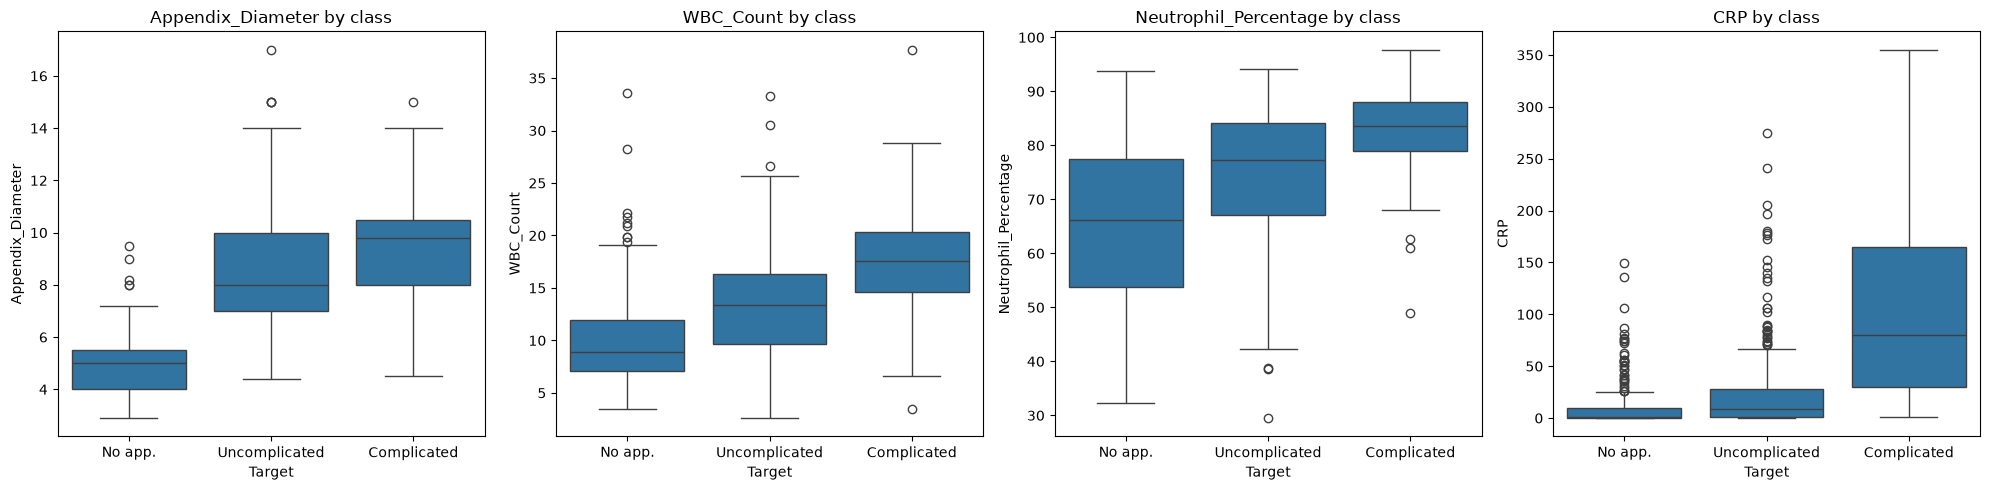

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, feature in zip(axes, ["Appendix_Diameter", "WBC_Count", "Neutrophil_Percentage", "CRP"]):
    sns.boxplot(data=train_analysis, x="Target", y=feature, ax=ax)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["No app.", "Uncomplicated", "Complicated"])
    ax.set_title(f"{feature} by class")
plt.tight_layout()
plt.show()


In [17]:
# Is missingness related to the class?
for col in ["Appendix_Diameter", "RBC_in_Urine", "Ketones_in_Urine", "WBC_in_Urine",
            "Ipsilateral_Rebound_Tenderness", "Neutrophil_Percentage", "Free_Fluids"]:
    table = pd.crosstab(y_train, X_train[col].isna(), normalize="index") * 100
    table = table.rename(columns={False: "Not missing %", True: "Missing %"})
    print(f"\n{col}")
    print(table.round(1).to_string())



Appendix_Diameter
Appendix_Diameter  Not missing %  Missing %
Target                                     
0                           40.6       59.4
1                           87.7       12.3
2                           58.5       41.5

RBC_in_Urine
RBC_in_Urine  Not missing %  Missing %
Target                                
0                      81.1       18.9
1                      73.9       26.1
2                      57.4       42.6

Ketones_in_Urine
Ketones_in_Urine  Not missing %  Missing %
Target                                    
0                          83.1       16.9
1                          74.3       25.7
2                          57.4       42.6

WBC_in_Urine
WBC_in_Urine  Not missing %  Missing %
Target                                
0                      83.1       16.9
1                      74.3       25.7
2                      57.4       42.6

Ipsilateral_Rebound_Tenderness
Ipsilateral_Rebound_Tenderness  Not missing %  Missing %
Target               

## 3.4 Preprocessing pipeline (fitted on training data only)
- Numerical: median imputation **+ missing-value indicator columns**
- Categorical: fill with "Missing" + one-hot encoding

32 input columns → **90 features** (13 numerical + 12 missing indicators + 65 one-hot columns).

In [18]:
numerical_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True))]), numerical_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_cols),
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Numerical:", len(numerical_cols), "| Categorical:", len(categorical_cols))
print("Processed train:", X_train_processed.shape, "| test:", X_test_processed.shape)
print("NaN in train/test:", np.isnan(X_train_processed).sum(), np.isnan(X_test_processed).sum())

# Scaled copy for distance/linear models (LR, SVM, KNN)
scaler_clin = StandardScaler().fit(X_train_processed)
X_train_scaled = scaler_clin.transform(X_train_processed)
X_test_scaled = scaler_clin.transform(X_test_processed)


Numerical: 13 | Categorical: 19
Processed train: (624, 90) | test: (156, 90)
NaN in train/test: 0 0


# 4. Clinical machine-learning models
Each model is trained on the 624 training patients and evaluated on the 156 test patients.

In [19]:
clinical_results = {}

def evaluate(name, y_true, y_pred, store=clinical_results, show=True):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred).astype(int).ravel()
    store[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "Complicated_Precision": precision_score(y_true, y_pred, labels=[2], average="macro", zero_division=0),
        "Complicated_Recall": recall_score(y_true, y_pred, labels=[2], average="macro", zero_division=0),
        "Complicated_F1": f1_score(y_true, y_pred, labels=[2], average="macro", zero_division=0),
    }
    if show:
        print(f"{'=' * 60}\n{name} — Accuracy {store[name]['Accuracy']:.4f} | Macro F1 {store[name]['Macro_F1']:.4f}")
        print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
        print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

def show_importance(model, top=20):
    imp = pd.DataFrame({"Feature": feature_names, "Importance": model.feature_importances_})
    print(imp.sort_values("Importance", ascending=False).head(top).to_string(index=False))


## 4.1 Logistic Regression (baseline)

In [20]:
lr_model = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED)
lr_model.fit(X_train_scaled, y_train)
evaluate("Logistic Regression", y_test, lr_model.predict(X_test_scaled))


Logistic Regression — Accuracy 0.7756 | Macro F1 0.7270
                            precision    recall  f1-score   support

           No appendicitis      0.864     0.905     0.884        63
Uncomplicated appendicitis      0.773     0.739     0.756        69
  Complicated appendicitis      0.542     0.542     0.542        24

                  accuracy                          0.776       156
                 macro avg      0.726     0.729     0.727       156
              weighted avg      0.774     0.776     0.774       156

Confusion matrix:
 [[57  5  1]
 [ 8 51 10]
 [ 1 10 13]]


## 4.2 Random Forest

In [21]:
rf_model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf_model.fit(X_train_processed, y_train)
evaluate("Random Forest", y_test, rf_model.predict(X_test_processed))
print("\nTop 20 Random Forest features:")
show_importance(rf_model)


Random Forest — Accuracy 0.8269 | Macro F1 0.7705
                            precision    recall  f1-score   support

           No appendicitis      0.947     0.857     0.900        63
Uncomplicated appendicitis      0.778     0.913     0.840        69
  Complicated appendicitis      0.667     0.500     0.571        24

                  accuracy                          0.827       156
                 macro avg      0.797     0.757     0.770       156
              weighted avg      0.829     0.827     0.823       156

Confusion matrix:
 [[54  7  2]
 [ 2 63  4]
 [ 1 11 12]]

Top 20 Random Forest features:
                                    Feature  Importance
                     num__Appendix_Diameter    0.086509
                                   num__CRP    0.079878
                             num__WBC_Count    0.070717
                 num__Neutrophil_Percentage    0.041710
cat__Ipsilateral_Rebound_Tenderness_Missing    0.038577
                      num__Body_Temperature    

In [22]:
# Hyperparameter tuning with 5-fold CV (macro F1) on the training data
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=SEED, class_weight="balanced"),
    param_grid={"n_estimators": [200, 300, 500], "max_depth": [None, 10, 20],
                "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4]},
    scoring="f1_macro", cv=5, n_jobs=-1, verbose=0)
rf_grid.fit(X_train_processed, y_train)
print("Best parameters:", rf_grid.best_params_)
print("Best CV macro F1:", round(rf_grid.best_score_, 4))
evaluate("Random Forest (tuned)", y_test, rf_grid.best_estimator_.predict(X_test_processed))


Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV macro F1: 0.7704
Random Forest (tuned) — Accuracy 0.8205 | Macro F1 0.7813
                            precision    recall  f1-score   support

           No appendicitis      0.963     0.825     0.889        63
Uncomplicated appendicitis      0.782     0.884     0.830        69
  Complicated appendicitis      0.625     0.625     0.625        24

                  accuracy                          0.821       156
                 macro avg      0.790     0.778     0.781       156
              weighted avg      0.831     0.821     0.822       156

Confusion matrix:
 [[52  9  2]
 [ 1 61  7]
 [ 1  8 15]]


## 4.3 XGBoost

In [23]:
xgb_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, objective="multi:softprob", eval_metric="mlogloss",
                          random_state=SEED, n_jobs=-1)
xgb_model.fit(X_train_processed, y_train)
y_pred_xgb = xgb_model.predict(X_test_processed)
evaluate("XGBoost", y_test, y_pred_xgb)
print("\nTop 20 XGBoost features:")
show_importance(xgb_model)


XGBoost — Accuracy 0.8590 | Macro F1 0.8084
                            precision    recall  f1-score   support

           No appendicitis      0.935     0.921     0.928        63
Uncomplicated appendicitis      0.818     0.913     0.863        69
  Complicated appendicitis      0.765     0.542     0.634        24

                  accuracy                          0.859       156
                 macro avg      0.839     0.792     0.808       156
              weighted avg      0.857     0.859     0.854       156

Confusion matrix:
 [[58  4  1]
 [ 3 63  3]
 [ 1 10 13]]

Top 20 XGBoost features:
                                      Feature  Importance
                      cat__Appendix_on_US_yes    0.064502
                       cat__Appendix_on_US_no    0.059057
       cat__Ipsilateral_Rebound_Tenderness_no    0.053352
                       num__Appendix_Diameter    0.041682
cat__Contralateral_Rebound_Tenderness_Missing    0.035897
                cat__Loss_of_Appetite_Missing  

In [24]:
# Error analysis: which classes does XGBoost get wrong?
error_analysis = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred_xgb})
error_analysis["Correct"] = error_analysis["Actual"] == error_analysis["Predicted"]
print("Wrong predictions by actual class:")
print(error_analysis[~error_analysis["Correct"]]["Actual"].value_counts().sort_index().to_string())
print("\nHow the missed complicated cases were classified:")
print(error_analysis[(error_analysis["Actual"] == 2) & ~error_analysis["Correct"]]["Predicted"]
      .value_counts().sort_index().to_string())


Wrong predictions by actual class:
Actual
0     5
1     6
2    11

How the missed complicated cases were classified:
Predicted
0     1
1    10


In [25]:
xgb_grid = GridSearchCV(
    XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", random_state=SEED, n_jobs=-1),
    param_grid={"n_estimators": [200, 300, 500], "max_depth": [3, 4, 5],
                "learning_rate": [0.03, 0.05, 0.1], "min_child_weight": [1, 3, 5]},
    scoring="f1_macro", cv=5, n_jobs=-1, verbose=0)
xgb_grid.fit(X_train_processed, y_train)
best_xgb = xgb_grid.best_estimator_
print("Best parameters:", xgb_grid.best_params_)
print("Best CV macro F1:", round(xgb_grid.best_score_, 4))
evaluate("XGBoost (tuned)", y_test, best_xgb.predict(X_test_processed))


Best parameters: {'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300}
Best CV macro F1: 0.7714
XGBoost (tuned) — Accuracy 0.8654 | Macro F1 0.7985
                            precision    recall  f1-score   support

           No appendicitis      0.952     0.937     0.944        63
Uncomplicated appendicitis      0.812     0.942     0.872        69
  Complicated appendicitis      0.786     0.458     0.579        24

                  accuracy                          0.865       156
                 macro avg      0.850     0.779     0.798       156
              weighted avg      0.865     0.865     0.856       156

Confusion matrix:
 [[59  3  1]
 [ 2 65  2]
 [ 1 12 11]]


### Class weighting for complicated appendicitis
*Exploratory:* compares several class-2 weights on the test set. Because the weight is chosen by
looking at test results, this is **not** used for the final reported results.

In [26]:
rows = []
for weight in [1.0, 1.5, 2.0, 2.5, 3.0]:
    sw = np.where(y_train == 2, weight, 1.0)
    m = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.03, min_child_weight=5,
                      objective="multi:softprob", eval_metric="mlogloss", random_state=SEED, n_jobs=-1)
    m.fit(X_train_processed, y_train, sample_weight=sw)
    p = m.predict(X_test_processed)
    rows.append({"Class_2_Weight": weight, "Accuracy": accuracy_score(y_test, p),
                 "Macro_F1": f1_score(y_test, p, average="macro"),
                 "Complicated_Recall": recall_score(y_test, p, labels=[2], average="macro"),
                 "Complicated_F1": f1_score(y_test, p, labels=[2], average="macro")})
display(pd.DataFrame(rows).round(4))


,Class_2_Weight,Accuracy,Macro_F1,Complicated_Recall,Complicated_F1
0,1.0,0.8718,0.8245,0.5417,0.6667
1,1.5,0.8590,0.8086,0.5417,0.6341
2,2.0,0.8397,0.7919,0.6250,0.6000
3,2.5,0.8269,0.7833,0.6667,0.5926
4,3.0,0.8269,0.7873,0.7083,0.6071


## 4.4 Other models: SVM, Extra Trees, KNN, LightGBM, CatBoost, HistGradientBoosting

In [27]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED)
svm_model.fit(X_train_scaled, y_train)
evaluate("SVM", y_test, svm_model.predict(X_test_scaled))


SVM — Accuracy 0.7500 | Macro F1 0.7136
                            precision    recall  f1-score   support

           No appendicitis      0.821     0.873     0.846        63
Uncomplicated appendicitis      0.783     0.681     0.729        69
  Complicated appendicitis      0.517     0.625     0.566        24

                  accuracy                          0.750       156
                 macro avg      0.707     0.726     0.714       156
              weighted avg      0.758     0.750     0.751       156

Confusion matrix:
 [[55  6  2]
 [10 47 12]
 [ 2  7 15]]


In [28]:
extra_model = ExtraTreesClassifier(n_estimators=500, class_weight="balanced", random_state=SEED, n_jobs=-1)
extra_model.fit(X_train_processed, y_train)
evaluate("Extra Trees", y_test, extra_model.predict(X_test_processed))


Extra Trees — Accuracy 0.7436 | Macro F1 0.6560
                            precision    recall  f1-score   support

           No appendicitis      0.922     0.746     0.825        63
Uncomplicated appendicitis      0.681     0.899     0.775        69
  Complicated appendicitis      0.500     0.292     0.368        24

                  accuracy                          0.744       156
                 macro avg      0.701     0.645     0.656       156
              weighted avg      0.750     0.744     0.732       156

Confusion matrix:
 [[47 14  2]
 [ 2 62  5]
 [ 2 15  7]]


In [29]:
knn_model = KNeighborsClassifier(n_neighbors=7, weights="distance", metric="euclidean")
knn_model.fit(X_train_scaled, y_train)
evaluate("KNN", y_test, knn_model.predict(X_test_scaled))


KNN — Accuracy 0.6154 | Macro F1 0.5211
                            precision    recall  f1-score   support

           No appendicitis      0.737     0.667     0.700        63
Uncomplicated appendicitis      0.575     0.725     0.641        69
  Complicated appendicitis      0.333     0.167     0.222        24

                  accuracy                          0.615       156
                 macro avg      0.548     0.519     0.521       156
              weighted avg      0.603     0.615     0.600       156

Confusion matrix:
 [[42 19  2]
 [13 50  6]
 [ 2 18  4]]


In [30]:
lgb_model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                           class_weight="balanced", random_state=SEED, verbosity=-1)
lgb_model.fit(X_train_processed, y_train)
evaluate("LightGBM", y_test, lgb_model.predict(X_test_processed))


LightGBM — Accuracy 0.8526 | Macro F1 0.8058
                            precision    recall  f1-score   support

           No appendicitis      0.935     0.921     0.928        63
Uncomplicated appendicitis      0.824     0.884     0.853        69
  Complicated appendicitis      0.700     0.583     0.636        24

                  accuracy                          0.853       156
                 macro avg      0.820     0.796     0.806       156
              weighted avg      0.850     0.853     0.850       156

Confusion matrix:
 [[58  4  1]
 [ 3 61  5]
 [ 1  9 14]]


In [31]:
cat_model = CatBoostClassifier(iterations=300, depth=5, learning_rate=0.03, l2_leaf_reg=5,
                               loss_function="MultiClass", random_seed=SEED, verbose=0,
                               allow_writing_files=False)
cat_model.fit(X_train_processed, y_train)
evaluate("CatBoost", y_test, cat_model.predict(X_test_processed))


CatBoost — Accuracy 0.8526 | Macro F1 0.8011
                            precision    recall  f1-score   support

           No appendicitis      0.948     0.873     0.909        63
Uncomplicated appendicitis      0.786     0.957     0.863        69
  Complicated appendicitis      0.857     0.500     0.632        24

                  accuracy                          0.853       156
                 macro avg      0.864     0.777     0.801       156
              weighted avg      0.862     0.853     0.846       156

Confusion matrix:
 [[55  7  1]
 [ 2 66  1]
 [ 1 11 12]]


In [32]:
hgb_model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=6, random_state=SEED)
hgb_model.fit(X_train_processed, y_train)
evaluate("HistGradientBoosting", y_test, hgb_model.predict(X_test_processed))


HistGradientBoosting — Accuracy 0.8205 | Macro F1 0.7346
                            precision    recall  f1-score   support

           No appendicitis      0.950     0.905     0.927        63
Uncomplicated appendicitis      0.785     0.899     0.838        69
  Complicated appendicitis      0.529     0.375     0.439        24

                  accuracy                          0.821       156
                 macro avg      0.755     0.726     0.735       156
              weighted avg      0.812     0.821     0.812       156

Confusion matrix:
 [[57  3  3]
 [ 2 62  5]
 [ 1 14  9]]


## 4.5 Clinical model comparison
Computed from the predictions above (not typed in by hand).

,Accuracy,Macro_F1,Weighted_F1,Complicated_Precision,Complicated_Recall,Complicated_F1
XGBoost,0.8590,0.8084,0.8540,0.7647,0.5417,0.6341
LightGBM,0.8526,0.8058,0.8500,0.7000,0.5833,0.6364
CatBoost,0.8526,0.8011,0.8459,0.8571,0.5000,0.6316
XGBoost (tuned),0.8654,0.7985,0.8562,0.7857,0.4583,0.5789
Random Forest (tuned),0.8205,0.7813,0.8222,0.6250,0.6250,0.6250
Random Forest,0.8269,0.7705,0.8229,0.6667,0.5000,0.5714
HistGradientBoosting,0.8205,0.7346,0.8124,0.5294,0.3750,0.4390
Logistic Regression,0.7756,0.7270,0.7744,0.5417,0.5417,0.5417
SVM,0.7500,0.7136,0.7511,0.5172,0.6250,0.5660
Extra Trees,0.7436,0.6560,0.7325,0.5000,0.2917,0.3684


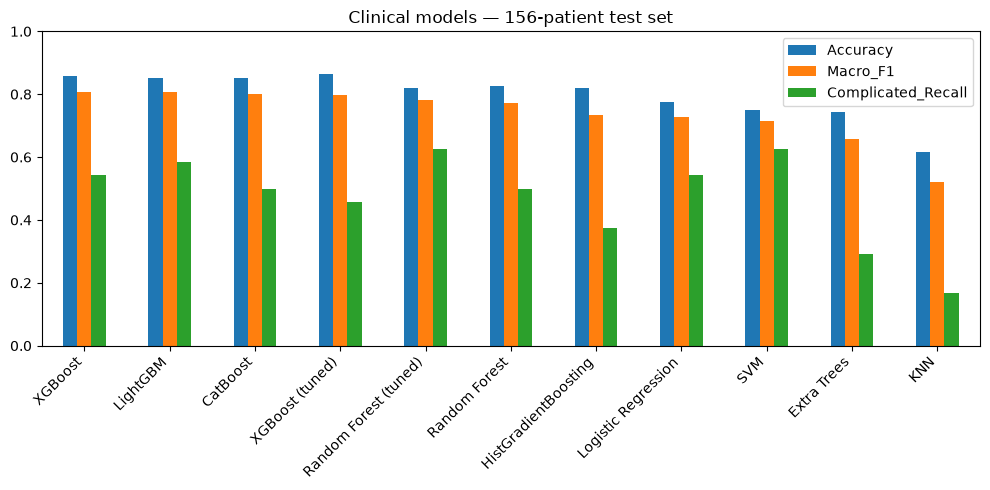

In [33]:
clinical_comparison = (pd.DataFrame(clinical_results).T
                       .sort_values("Macro_F1", ascending=False).round(4))
display(clinical_comparison)
clinical_comparison.to_csv(os.path.join(RESULTS, "dev_clinical_model_comparison.csv"))

plt.figure(figsize=(10, 5))
clinical_comparison[["Accuracy", "Macro_F1", "Complicated_Recall"]].plot(kind="bar", ax=plt.gca())
plt.title("Clinical models — 156-patient test set")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [34]:
joblib.dump(best_xgb, os.path.join(RESULTS, "clinical_xgb.pkl"))
joblib.dump(preprocessor, os.path.join(RESULTS, "clinical_preprocessor.pkl"))
print("Saved tuned XGBoost and preprocessor to", RESULTS)


Saved tuned XGBoost and preprocessor to C:\Users\MUSAIB\Desktop\Appendixai\results


# 5. Ultrasound images
## 5.1 Image inventory

In [35]:
image_files = sorted(f for f in os.listdir(IMG_DIR) if f.lower().endswith((".bmp", ".png", ".jpg", ".jpeg")))
print("Total ultrasound images:", len(image_files))
print("Formats:", dict(Counter(os.path.splitext(f)[1].lower() for f in image_files)))
print("First 10 filenames:", image_files[:10])


Total ultrasound images: 2097
Formats: {'.png': 31, '.bmp': 2064, '.jpg': 2}
First 10 filenames: ['1.1 RLQ_Pathological Lymphnodes.png', '1.2 Ileitis.png', '1.3 Mesenterial Lymphadenitis.png', '1.4 Appendix.png', '1.4 Appendix.png.bmp', '1.5 Appendix, surrounding tissue reaction.png', '10.1 Appendix and surrounding free fluis.png', '10.2 Appendix and surrounding free fluis.png', '100.1 App_M.bmp', '100.2 RLQ.bmp']


## 5.2 Link images to patients
The number before the first dot in each filename is the patient's `US_Number`.

In [36]:
image_ids = [int(re.match(r"^(\d+)\.", f).group(1)) for f in image_files]
image_id_set = set(image_ids)
us_number_set = set(df_raw["US_Number"].dropna().astype(int))
matched = image_id_set & us_number_set

print("Unique image IDs          :", len(image_id_set))
print("Unique US_Number values   :", len(us_number_set))
print("Matched patients          :", len(matched))
print("Image IDs with no record  :", len(image_id_set - us_number_set))
print("US_Numbers with no images :", len(us_number_set - image_id_set))
print("Images of matched patients:", sum(i in matched for i in image_ids))


Unique image IDs          : 707
Unique US_Number values   : 760
Matched patients          : 579
Image IDs with no record  : 128
US_Numbers with no images : 181
Images of matched patients: 1727


In [37]:
# Patient -> target (uses the same target definition as the clinical data)
usable = df_full[df_full["US_Number"].notna()].copy()
usable["US_Number"] = usable["US_Number"].astype(int)
usable = usable[usable["US_Number"].isin(matched)]
subject_to_target = dict(zip(usable["US_Number"], usable["Target"]))

labeled_image_records = [
    {"filename": f, "subject_id": sid, "target": subject_to_target[sid]}
    for f, sid in zip(image_files, image_ids) if sid in subject_to_target
]
records_df = pd.DataFrame(labeled_image_records)
summary = records_df.groupby("target").agg(Patients=("subject_id", "nunique"), Images=("filename", "count"))
summary.index = CLASS_NAMES
display(summary)
print("Total:", records_df["subject_id"].nunique(), "patients,", len(records_df), "images")


,Patients,Images
No appendicitis,196,382
Uncomplicated appendicitis,286,1082
Complicated appendicitis,96,257


Total: 578 patients, 1721 images


## 5.3 Image quality checks

In [38]:
hash_to_files = defaultdict(list)
mode_counts, size_counts, failed = Counter(), Counter(), []
for rec in labeled_image_records:
    path = os.path.join(IMG_DIR, rec["filename"])
    try:
        with open(path, "rb") as fh:
            hash_to_files[hashlib.md5(fh.read()).hexdigest()].append(rec["filename"])
        with Image.open(path) as img:
            mode_counts[img.mode] += 1
            size_counts[img.size] += 1
    except Exception as e:
        failed.append((rec["filename"], str(e)))

dup_groups = [v for v in hash_to_files.values() if len(v) > 1]
print("Exact duplicate groups:", len(dup_groups))
print("Images that failed to open:", len(failed))
print("Image modes:", dict(mode_counts))
print("Unique image sizes:", len(size_counts), "| most common:", size_counts.most_common(5))


Exact duplicate groups: 0
Images that failed to open: 0
Image modes: {'RGB': 1710, 'RGBA': 11}
Unique image sizes: 159 | most common: [((716, 537), 886), ((799, 582), 67), ((716, 520), 49), ((800, 584), 34), ((716, 521), 33)]


## 5.4 Patient-level split (70% train / 15% validation / 15% test)
Splitting by patient means no patient's images appear in more than one set.

In [39]:
subject_df = pd.DataFrame({"subject_id": list(subject_to_target.keys()),
                           "Target": list(subject_to_target.values())})
train_subjects, temp_subjects = train_test_split(subject_df, test_size=0.30, random_state=SEED,
                                                 stratify=subject_df["Target"])
val_subjects, test_subjects = train_test_split(temp_subjects, test_size=0.50, random_state=SEED,
                                               stratify=temp_subjects["Target"])
train_ids, val_ids, test_ids = (set(train_subjects["subject_id"]), set(val_subjects["subject_id"]),
                                set(test_subjects["subject_id"]))
print("Patients — train/val/test:", len(train_ids), len(val_ids), len(test_ids))
print("Overlaps:", len(train_ids & val_ids), len(train_ids & test_ids), len(val_ids & test_ids))

train_images = [r for r in labeled_image_records if r["subject_id"] in train_ids]
val_images = [r for r in labeled_image_records if r["subject_id"] in val_ids]
test_images = [r for r in labeled_image_records if r["subject_id"] in test_ids]
print("Images — train/val/test:", len(train_images), len(val_images), len(test_images))


Patients — train/val/test: 404 87 87
Overlaps: 0 0 0
Images — train/val/test: 1230 244 247


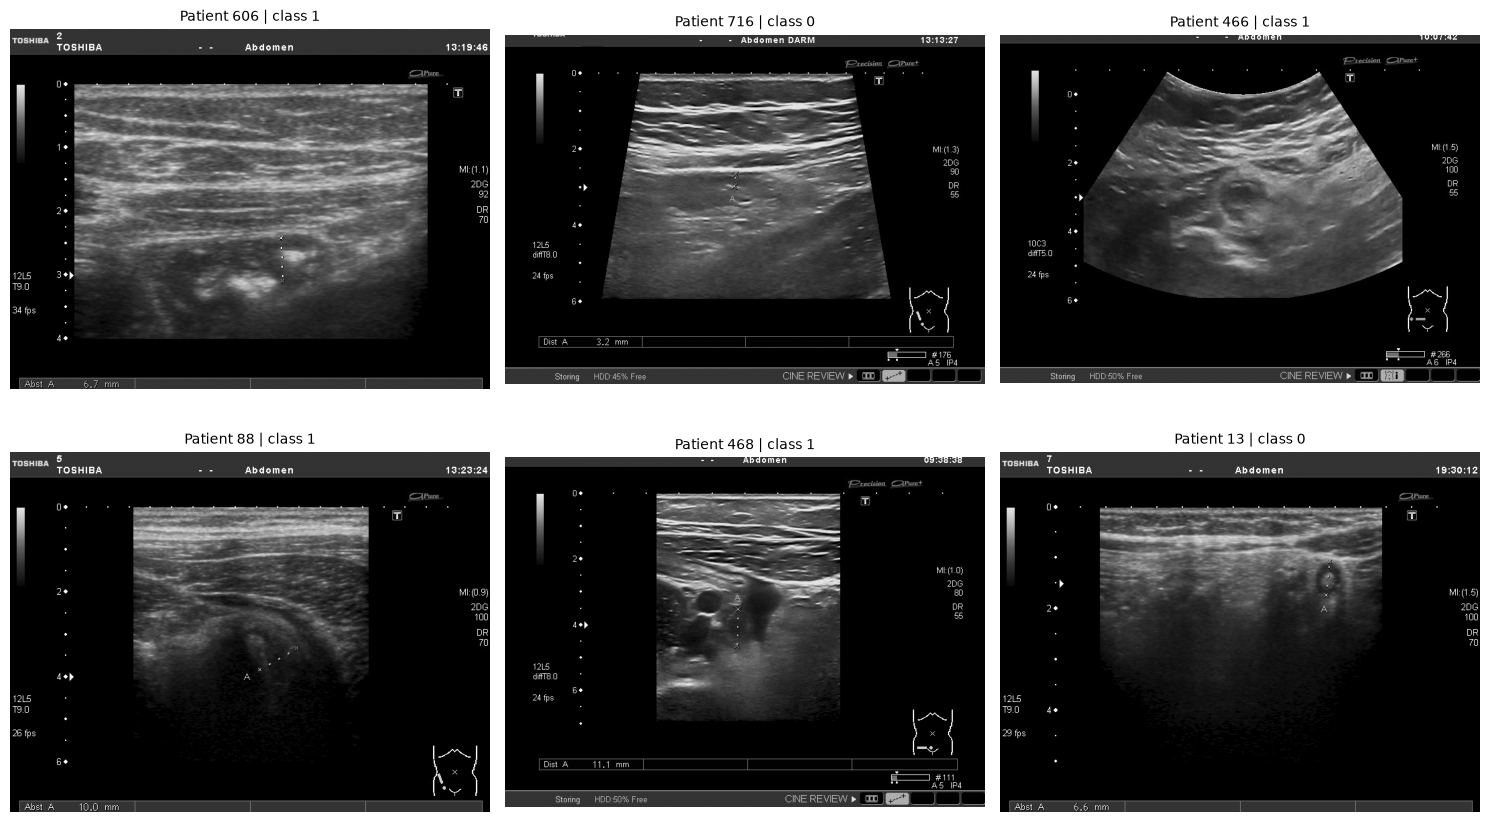

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
rng = np.random.default_rng(SEED)
for ax, idx in zip(axes.ravel(), rng.choice(len(train_images), 6, replace=False)):
    rec = train_images[idx]
    ax.imshow(Image.open(os.path.join(IMG_DIR, rec["filename"])).convert("L"), cmap="gray")
    ax.set_title(f"Patient {rec['subject_id']} | class {rec['target']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()


# 6. ResNet18 image model
## 6.1 Dataset, transforms and DataLoaders
Images are resized with their aspect ratio preserved, padded to 224×224 and normalized with
ImageNet statistics. Training images get light augmentation.

In [41]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def letterbox(path, size=224):
    img = Image.open(path).convert("RGB")
    img.thumbnail((size, size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
    return canvas

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

class UltrasoundDataset(Dataset):
    def __init__(self, records, image_dir, transform):
        self.records, self.image_dir, self.transform = records, image_dir, transform
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        rec = self.records[idx]
        image = self.transform(letterbox(os.path.join(self.image_dir, rec["filename"])))
        return image, torch.tensor(rec["target"], dtype=torch.long)

def make_loader(records, transform, shuffle):
    return DataLoader(UltrasoundDataset(records, IMG_DIR, transform), batch_size=32, shuffle=shuffle,
                      num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g)

train_loader = make_loader(train_images, train_transform, shuffle=True)
val_loader = make_loader(val_images, eval_transform, shuffle=False)
test_loader = make_loader(test_images, eval_transform, shuffle=False)

images, labels = next(iter(train_loader))
print("Batch:", images.shape, "| labels:", labels[:10].tolist())
print("Batches — train/val/test:", len(train_loader), len(val_loader), len(test_loader))


Batch: torch.Size([32, 3, 224, 224]) | labels: [2, 1, 1, 1, 0, 1, 1, 1, 0, 1]
Batches — train/val/test: 39 8 8


## 6.2 Transfer learning: frozen ResNet18 backbone, trainable classifier
The ImageNet backbone is frozen (the dataset is too small to fine-tune all layers safely).
Only the final 3-class layer is trained, with class-weighted cross-entropy.

In [42]:
frozen_model = models.resnet18(weights=None)
frozen_model.load_state_dict(torch.load(WEIGHTS, map_location="cpu"))
for p in frozen_model.parameters():
    p.requires_grad = False
frozen_model.fc = nn.Linear(frozen_model.fc.in_features, 3)     # new layer is trainable
frozen_model = frozen_model.to(DEVICE)

class_counts = np.bincount([r["target"] for r in train_images], minlength=3)
image_class_weights = torch.tensor(len(train_images) / (3 * class_counts), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=image_class_weights)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, frozen_model.parameters()), lr=1e-3)

print("Trainable parameters:", sum(p.numel() for p in frozen_model.parameters() if p.requires_grad))
print("Class counts:", class_counts, "| weights:", image_class_weights.cpu().numpy().round(3))


Trainable parameters: 1539
Class counts: [263 780 187] | weights: [1.559 0.526 2.193]


In [43]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    best_val_loss, best_state = float("inf"), copy.deepcopy(model.state_dict())
    for epoch in range(num_epochs):
        t0 = time.time()
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss += criterion(model(xb), yb).item() * xb.size(0)
        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss, best_state = val_loss, copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1}/{num_epochs} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | {time.time() - t0:.0f}s")
    model.load_state_dict(best_state)
    return model, best_val_loss

frozen_model, best_val_loss = train_model(frozen_model, train_loader, val_loader, criterion, optimizer, num_epochs=5)
print("Best validation loss:", round(best_val_loss, 4))


Epoch 1/5 | train loss 1.1206 | val loss 1.0981 | 17s


Epoch 2/5 | train loss 1.0401 | val loss 1.0745 | 18s


Epoch 3/5 | train loss 0.9975 | val loss 1.0772 | 18s


Epoch 4/5 | train loss 1.0108 | val loss 1.0647 | 18s


Epoch 5/5 | train loss 0.9827 | val loss 1.0611 | 18s
Best validation loss: 1.0611


In [44]:
# Validation performance: per image and per patient (averaging a patient's image probabilities)
frozen_model.eval()
val_probs = []
with torch.no_grad():
    for xb, _ in val_loader:
        val_probs.append(torch.softmax(frozen_model(xb.to(DEVICE)), 1).cpu().numpy())
val_probs = np.concatenate(val_probs)
val_true = np.array([r["target"] for r in val_images])
val_sids = np.array([r["subject_id"] for r in val_images])

print("IMAGE level — accuracy:", round(accuracy_score(val_true, val_probs.argmax(1)), 4),
      "| macro F1:", round(f1_score(val_true, val_probs.argmax(1), average="macro"), 4))

pids = np.unique(val_sids)
p_pred = np.array([val_probs[val_sids == p].mean(0).argmax() for p in pids])
p_true = np.array([subject_to_target[p] for p in pids])
print("PATIENT level — accuracy:", round(accuracy_score(p_true, p_pred), 4),
      "| macro F1:", round(f1_score(p_true, p_pred, average="macro"), 4))
print(confusion_matrix(p_true, p_pred))


IMAGE level — accuracy: 0.4016 | macro F1: 0.3786
PATIENT level — accuracy: 0.4023 | macro F1: 0.4007
[[12 11  6]
 [ 9 14 20]
 [ 5  1  9]]


## 6.3 Extract 512-D image features and build patient-level vectors
Features are extracted **without augmentation** for all three sets so that every patient is
represented the same way. Each patient's images are combined by element-wise mean and max → 1024-D.

In [45]:
feature_extractor = nn.Sequential(*list(frozen_model.children())[:-1]).to(DEVICE).eval()

def extract_features(records):
    loader = make_loader(records, eval_transform, shuffle=False)
    feats = []
    with torch.no_grad():
        for xb, _ in loader:
            feats.append(feature_extractor(xb.to(DEVICE)).flatten(1).cpu().numpy())
    return np.concatenate(feats), np.array([r["subject_id"] for r in records])

train_features, train_subject_ids = extract_features(train_images)
val_features, val_subject_ids = extract_features(val_images)
test_features, test_subject_ids = extract_features(test_images)
print("Image features — train/val/test:", train_features.shape, val_features.shape, test_features.shape)

def aggregate_mean_max(features, subject_ids):
    ids = np.unique(subject_ids)
    agg = np.stack([np.concatenate([features[subject_ids == i].mean(0), features[subject_ids == i].max(0)])
                    for i in ids])
    return agg.astype(np.float32), ids

train_us, train_us_ids = aggregate_mean_max(train_features, train_subject_ids)
val_us, val_us_ids = aggregate_mean_max(val_features, val_subject_ids)
test_us, test_us_ids = aggregate_mean_max(test_features, test_subject_ids)
y_train_us = np.array([subject_to_target[i] for i in train_us_ids])
y_val_us = np.array([subject_to_target[i] for i in val_us_ids])
y_test_us = np.array([subject_to_target[i] for i in test_us_ids])
us_feature_map = {int(i): v for ids_, X_ in [(train_us_ids, train_us), (val_us_ids, val_us), (test_us_ids, test_us)]
                  for i, v in zip(ids_, X_)}

print("Patient vectors — train/val/test:", train_us.shape, val_us.shape, test_us.shape)
print("Test class counts:", np.bincount(y_test_us, minlength=3))


Image features — train/val/test: (1230, 512) (244, 512) (247, 512)
Patient vectors — train/val/test: (404, 1024) (87, 1024) (87, 1024)
Test class counts: [30 43 14]


# 7. Ultrasound-only models
## 7.1 Mean+Max MLP (early stopping on the validation set)

In [46]:
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes=3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes))
    def forward(self, x):
        return self.network(x)

def train_mlp(X_tr, y_tr, X_va, y_va, lr=1e-3, epochs=30, patience=None, verbose=True):
    torch.manual_seed(SEED)
    model = MLP(X_tr.shape[1]).to(DEVICE)
    w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_tr)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr)),
                           batch_size=32, shuffle=True, generator=g)
    Xv = torch.tensor(X_va, dtype=torch.float32).to(DEVICE)
    yv = torch.tensor(y_va).to(DEVICE)
    best, best_state, wait, best_epoch = float("inf"), None, 0, 0
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_loader:
            opt.zero_grad()
            crit(model(xb.to(DEVICE)), yb.to(DEVICE)).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = crit(model(Xv), yv).item()
        if val_loss < best:
            best, best_state, wait, best_epoch = val_loss, copy.deepcopy(model.state_dict()), 0, epoch + 1
        else:
            wait += 1
            if patience and wait >= patience:
                break
    model.load_state_dict(best_state)
    if verbose:
        print(f"Best validation loss {best:.4f} at epoch {best_epoch}")
    return model

def predict_proba_torch(model, X):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.tensor(X, dtype=torch.float32).to(DEVICE)), 1).cpu().numpy()

us_results = {}
us_mlp = train_mlp(train_us, y_train_us, val_us, y_val_us, lr=1e-3, epochs=30)
evaluate("US Mean+Max MLP", y_test_us, predict_proba_torch(us_mlp, test_us).argmax(1), store=us_results)


Best validation loss 1.0323 at epoch 5
US Mean+Max MLP — Accuracy 0.4713 | Macro F1 0.4422
                            precision    recall  f1-score   support

           No appendicitis      0.571     0.800     0.667        30
Uncomplicated appendicitis      1.000     0.140     0.245        43
  Complicated appendicitis      0.282     0.786     0.415        14

                  accuracy                          0.471        87
                 macro avg      0.618     0.575     0.442        87
              weighted avg      0.737     0.471     0.418        87

Confusion matrix:
 [[24  0  6]
 [15  6 22]
 [ 3  0 11]]


## 7.2 Classical models on the 1024-D ultrasound vectors

In [47]:
us_models = {
    "US XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.03, min_child_weight=3,
                                subsample=0.8, colsample_bytree=0.8, objective="multi:softprob",
                                eval_metric="mlogloss", random_state=SEED, n_jobs=-1),
    "US Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                                               random_state=SEED, n_jobs=-1),
    "US SVM": Pipeline([("sc", StandardScaler()), ("svm", SVC(C=2.0, class_weight="balanced", random_state=SEED))]),
    "US LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, max_depth=4, num_leaves=15,
                                  min_child_samples=10, subsample=0.8, colsample_bytree=0.8,
                                  class_weight="balanced", random_state=SEED, verbosity=-1),
    "US Logistic Regression": Pipeline([("sc", StandardScaler()),
                                        ("lr", LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))]),
    "US KNN": KNeighborsClassifier(n_neighbors=15, weights="distance", metric="cosine"),
    "US Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.03, max_depth=3,
                                                       min_samples_leaf=5, subsample=0.8, random_state=SEED),
}
for name, m in us_models.items():
    m.fit(train_us, y_train_us)
    evaluate(name, y_test_us, m.predict(test_us), store=us_results, show=False)

majority = np.bincount(y_test_us).max() / len(y_test_us)
us_comparison = pd.DataFrame(us_results).T.sort_values("Macro_F1", ascending=False).round(4)
display(us_comparison)
print(f"Majority-class baseline accuracy: {majority:.4f}")


,Accuracy,Macro_F1,Weighted_F1,Complicated_Precision,Complicated_Recall,Complicated_F1
US LightGBM,0.6897,0.6521,0.6838,0.7500,0.4286,0.5455
US SVM,0.6667,0.6225,0.6634,0.5455,0.4286,0.4800
US XGBoost,0.6552,0.5922,0.6426,0.8000,0.2857,0.4211
US Random Forest,0.6207,0.5587,0.6119,0.5000,0.2857,0.3636
US Gradient Boosting,0.6322,0.5434,0.6142,0.5000,0.2143,0.3000
US Logistic Regression,0.5632,0.5198,0.5586,0.4286,0.4286,0.4286
US Mean+Max MLP,0.4713,0.4422,0.4177,0.2821,0.7857,0.4151
US KNN,0.4828,0.2796,0.3846,0.0000,0.0000,0.0000


Majority-class baseline accuracy: 0.4943


## 7.3 Attention pooling over each patient's images (multiple-instance learning)
Instead of a fixed mean/max, the model learns a weight for each ultrasound image of a patient.
The training patients are split 80/20 so early stopping uses validation patients only.

In [48]:
class PatientAttentionModel(nn.Module):
    def __init__(self, feature_dim=512, attention_dim=128, num_classes=3):
        super().__init__()
        self.attention = nn.Sequential(nn.Linear(feature_dim, attention_dim), nn.Tanh(),
                                       nn.Linear(attention_dim, 1))
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 3, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes))
    def forward(self, x):                                   # x: [n_images, 512]
        weights = torch.softmax(self.attention(x).squeeze(-1), dim=0)
        attention_pool = torch.sum(weights.unsqueeze(-1) * x, dim=0)
        combined = torch.cat([x.mean(0), x.max(0).values, attention_pool])
        return self.classifier(combined), weights

def make_bags(features, subject_ids, patient_ids):
    return [torch.tensor(features[subject_ids == p], dtype=torch.float32) for p in patient_ids]

att_train_ids, att_val_ids = train_test_split(train_us_ids, test_size=0.20, random_state=SEED, stratify=y_train_us)
train_bags = make_bags(train_features, train_subject_ids, att_train_ids)
val_bags = make_bags(train_features, train_subject_ids, att_val_ids)
test_bags = make_bags(test_features, test_subject_ids, test_us_ids)
train_bag_y = np.array([subject_to_target[p] for p in att_train_ids])
val_bag_y = np.array([subject_to_target[p] for p in att_val_ids])
print("Bags — train/val/test:", len(train_bags), len(val_bags), len(test_bags))

torch.manual_seed(SEED)
att_model = PatientAttentionModel().to(DEVICE)
att_w = torch.tensor(len(train_bag_y) / (3 * np.bincount(train_bag_y, minlength=3)), dtype=torch.float32).to(DEVICE)
att_crit = nn.CrossEntropyLoss(weight=att_w)
att_opt = torch.optim.AdamW(att_model.parameters(), lr=1e-4, weight_decay=1e-4)

best, best_state, wait = float("inf"), None, 0
for epoch in range(30):
    att_model.train()
    for i in np.random.permutation(len(train_bags)):
        att_opt.zero_grad()
        out, _ = att_model(train_bags[i].to(DEVICE))
        att_crit(out.unsqueeze(0), torch.tensor([train_bag_y[i]], device=DEVICE)).backward()
        att_opt.step()
    att_model.eval()
    with torch.no_grad():
        val_loss = np.mean([att_crit(att_model(b.to(DEVICE))[0].unsqueeze(0),
                                     torch.tensor([yv], device=DEVICE)).item()
                            for b, yv in zip(val_bags, val_bag_y)])
    if val_loss < best:
        best, best_state, wait = val_loss, copy.deepcopy(att_model.state_dict()), 0
    else:
        wait += 1
        if wait >= 7:
            print(f"Early stopping at epoch {epoch + 1}")
            break
att_model.load_state_dict(best_state)
print("Best validation loss:", round(best, 4))

att_model.eval()
with torch.no_grad():
    att_pred = [att_model(b.to(DEVICE))[0].argmax().item() for b in test_bags]
evaluate("US Attention MIL", y_test_us, att_pred, store=us_results)


Bags — train/val/test: 323 81 87


Early stopping at epoch 18
Best validation loss: 0.8514
US Attention MIL — Accuracy 0.6322 | Macro F1 0.5133
                            precision    recall  f1-score   support

           No appendicitis      0.652     0.500     0.566        30
Uncomplicated appendicitis      0.613     0.884     0.724        43
  Complicated appendicitis      1.000     0.143     0.250        14

                  accuracy                          0.632        87
                 macro avg      0.755     0.509     0.513        87
              weighted avg      0.689     0.632     0.593        87

Confusion matrix:
 [[15 15  0]
 [ 5 38  0]
 [ 3  9  2]]


# 8. Multimodal fusion (clinical + ultrasound)
## 8.1 Patient-aligned cohort
Clinical and ultrasound features must come from the **same patient**, so a new patient-level
split is made on the patients that have both. (As in the original notebook, the pool is the
ultrasound train + test patients; the 87 ultrasound-validation patients are not included.)

In [49]:
fusion_pool = np.array(sorted(train_ids | test_ids))
fusion_labels = np.array([subject_to_target[p] for p in fusion_pool])
fusion_train_ids, fusion_test_ids = train_test_split(fusion_pool, test_size=0.20, random_state=SEED,
                                                     stratify=fusion_labels)
print("Fusion cohort:", len(fusion_pool), "| train:", len(fusion_train_ids), "| test:", len(fusion_test_ids))
print("Train/test overlap:", len(set(fusion_train_ids) & set(fusion_test_ids)))

clinical_lookup = df_full.dropna(subset=["US_Number"]).assign(US_Number=lambda d: d["US_Number"].astype(int)) \
                         .set_index("US_Number")

def clinical_vectors(ids):
    return preprocessor.transform(clinical_lookup.loc[ids, preprocessor.feature_names_in_])

fusion_clinical_train = clinical_vectors(fusion_train_ids)
fusion_clinical_test = clinical_vectors(fusion_test_ids)
fusion_us_train = np.stack([us_feature_map[int(p)] for p in fusion_train_ids])
fusion_us_test = np.stack([us_feature_map[int(p)] for p in fusion_test_ids])
y_fusion_train = clinical_lookup.loc[fusion_train_ids, "Target"].to_numpy()
y_fusion_test = clinical_lookup.loc[fusion_test_ids, "Target"].to_numpy()

X_fusion_train = np.hstack([fusion_clinical_train, fusion_us_train])
X_fusion_test = np.hstack([fusion_clinical_test, fusion_us_test])
print("Fusion features — train:", X_fusion_train.shape, "| test:", X_fusion_test.shape)
print("Train classes:", np.bincount(y_fusion_train), "| test classes:", np.bincount(y_fusion_test))


Fusion cohort: 491 | train: 392 | test: 99
Train/test overlap: 0
Fusion features — train: (392, 1114) | test: (99, 1114)
Train classes: [133 194  65] | test classes: [34 49 16]


## 8.2 Fusion MLP (1114 → 256 → 128 → 3)
The training patients are split again into training and validation (80/20). The model with the
lowest validation loss is kept and evaluated **once** on the held-out test patients.

In [50]:
X_ft, X_fv, y_ft, y_fv = train_test_split(X_fusion_train, y_fusion_train, test_size=0.20,
                                          random_state=SEED, stratify=y_fusion_train)
print("Train/validation:", X_ft.shape, X_fv.shape)

fusion_model = train_mlp(X_ft, y_ft, X_fv, y_fv, lr=1e-4, epochs=50, patience=7)
fusion_proba = predict_proba_torch(fusion_model, X_fusion_test)
test_preds_np = fusion_proba.argmax(1)

fusion_results = {}
evaluate("Fusion MLP (clinical + US)", y_fusion_test, test_preds_np, store=fusion_results)

# Clinical-only XGBoost on the SAME fusion test patients, for a fair comparison
clin_same = XGBClassifier(**{k: v for k, v in best_xgb.get_params().items() if k != "n_jobs"}, n_jobs=-1)
clin_same.fit(fusion_clinical_train, y_fusion_train)
evaluate("Clinical XGBoost (same patients)", y_fusion_test, clin_same.predict(fusion_clinical_test),
         store=fusion_results, show=False)
display(pd.DataFrame(fusion_results).T.round(4))


Train/validation: (313, 1114) (79, 1114)


Best validation loss 0.6782 at epoch 50
Fusion MLP (clinical + US) — Accuracy 0.7172 | Macro F1 0.7090
                            precision    recall  f1-score   support

           No appendicitis      0.722     0.765     0.743        34
Uncomplicated appendicitis      0.767     0.673     0.717        49
  Complicated appendicitis      0.600     0.750     0.667        16

                  accuracy                          0.717        99
                 macro avg      0.697     0.729     0.709        99
              weighted avg      0.725     0.717     0.718        99

Confusion matrix:
 [[26  7  1]
 [ 9 33  7]
 [ 1  3 12]]


,Accuracy,Macro_F1,Weighted_F1,Complicated_Precision,Complicated_Recall,Complicated_F1
Fusion MLP (clinical + US),0.7172,0.7090,0.7179,0.6000,0.7500,0.6667
Clinical XGBoost (same patients),0.7576,0.6767,0.7404,0.7143,0.3125,0.4348


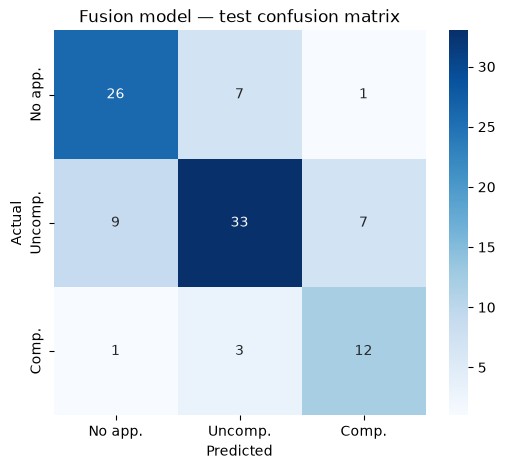

In [51]:
cm = confusion_matrix(y_fusion_test, test_preds_np)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No app.", "Uncomp.", "Comp."], yticklabels=["No app.", "Uncomp.", "Comp."])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fusion model — test confusion matrix")
plt.show()


# 9. Explainability
## 9.1 SHAP — clinical feature contributions to the fusion model

,Feature,Mean_Abs_SHAP_all_classes,Mean_Abs_SHAP_complicated
12,num__CRP,0.339090,0.485065
2,num__Height,0.147045,0.219769
7,num__Neutrophil_Percentage,0.089145,0.092227
11,num__Thrombocyte_Count,0.085094,0.079067
3,num__Weight,0.075128,0.075307
6,num__WBC_Count,0.071463,0.091885
4,num__Appendix_Diameter,0.022855,0.022423
0,num__Age,0.014714,0.021513
81,cat__Ipsilateral_Rebound_Tenderness_Missing,0.012902,0.016579
88,cat__Free_Fluids_no,0.012708,0.017092


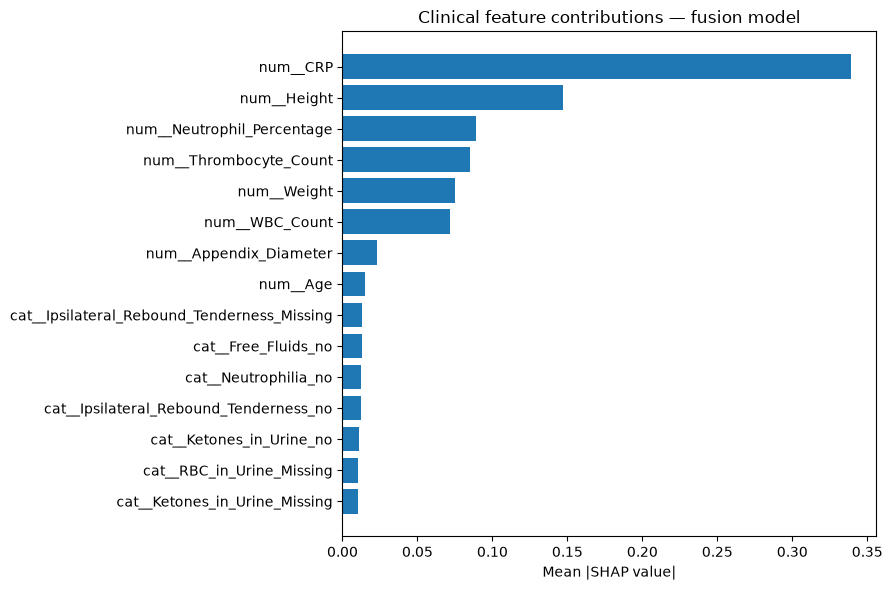

In [52]:
try:
    import shap
    background = torch.tensor(X_ft[:50], dtype=torch.float32).to(DEVICE)
    explain = torch.tensor(X_fusion_test[:20], dtype=torch.float32).to(DEVICE)
    explainer = shap.DeepExplainer(fusion_model, background)
    sv = explainer.shap_values(explain)
    sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)   # (samples, features, classes)
    n_clin = fusion_clinical_test.shape[1]
    shap_importance = pd.DataFrame({
        "Feature": feature_names,
        "Mean_Abs_SHAP_all_classes": np.abs(sv[:, :n_clin, :]).mean(axis=(0, 2)),
        "Mean_Abs_SHAP_complicated": np.abs(sv[:, :n_clin, 2]).mean(axis=0),
    }).sort_values("Mean_Abs_SHAP_all_classes", ascending=False)
    display(shap_importance.head(20))

    top = shap_importance.head(15).iloc[::-1]
    plt.figure(figsize=(9, 6))
    plt.barh(top["Feature"], top["Mean_Abs_SHAP_all_classes"])
    plt.xlabel("Mean |SHAP value|")
    plt.title("Clinical feature contributions — fusion model")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("SHAP skipped:", type(e).__name__, e)
    print("Install with: pip install shap   (pre-installed on Kaggle)")


## 9.2 Grad-CAM — which image regions drive the fusion prediction
The gradient of the final fusion output is passed back through the ResNet18 image branch.
Heatmaps show model attention, **not** a segmentation of the appendix.

Class 0 (No appendicitis): 26 correct test patients; showing patient 243


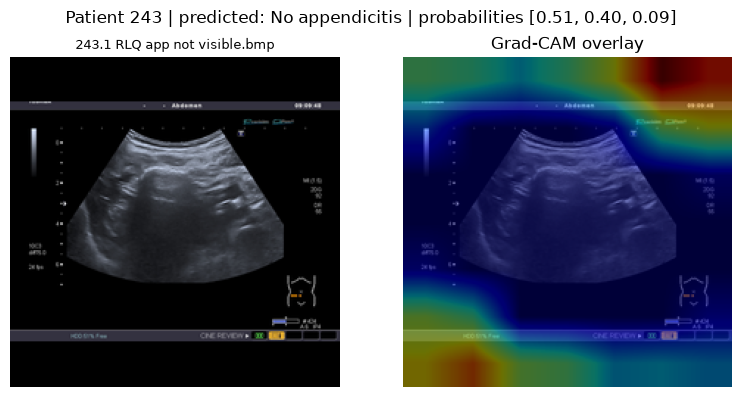

Class 1 (Uncomplicated appendicitis): 33 correct test patients; showing patient 619


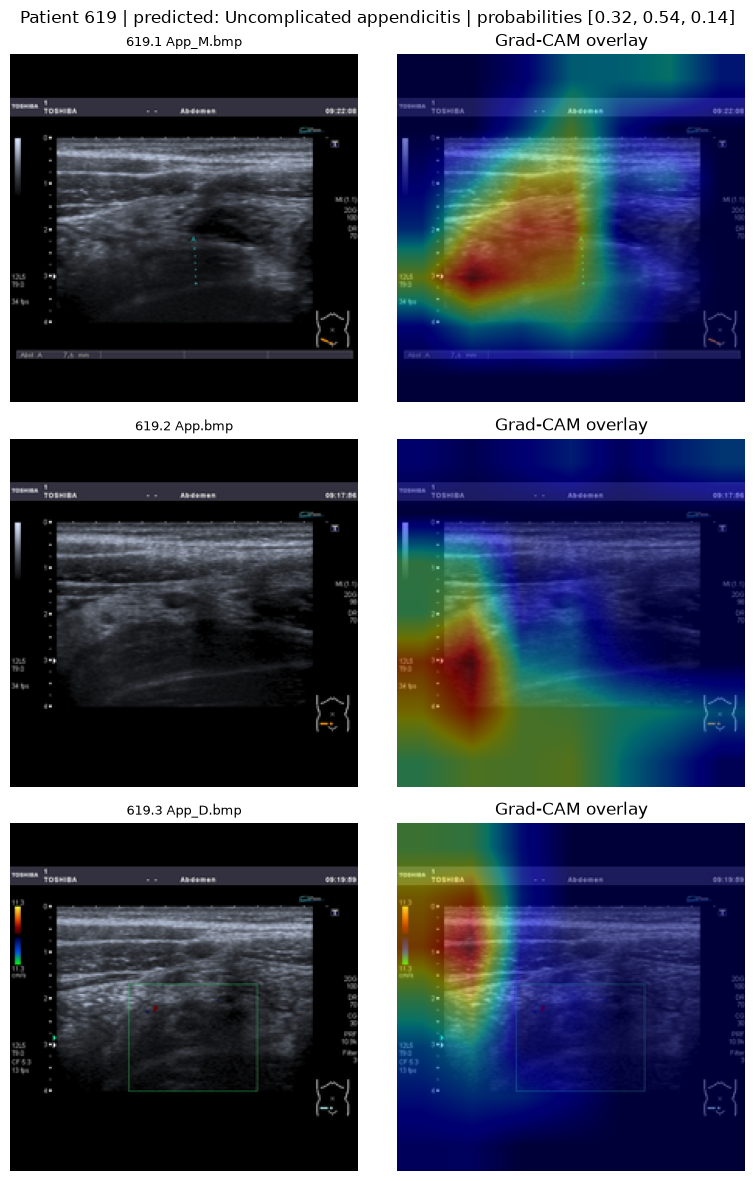

Class 2 (Complicated appendicitis): 12 correct test patients; showing patient 485


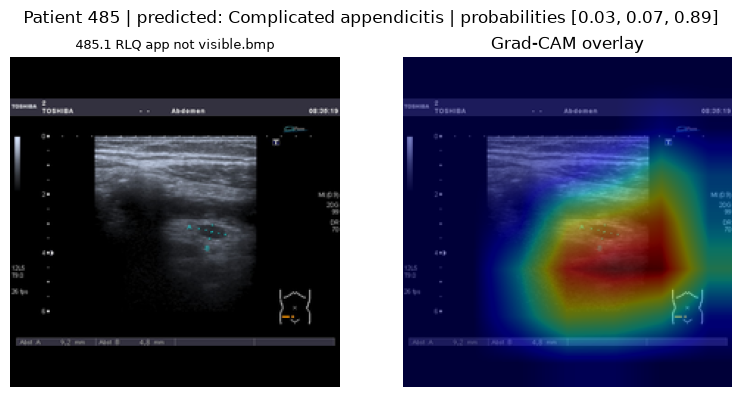

In [53]:
gradcam_resnet = copy.deepcopy(frozen_model)
gradcam_resnet.fc = nn.Identity()
gradcam_resnet = gradcam_resnet.to(DEVICE).eval()
for p in gradcam_resnet.parameters():
    p.requires_grad_(True)

fusion_test_id_to_index = {int(p): i for i, p in enumerate(fusion_test_ids)}
patient_image_records = defaultdict(list)
for rec in labeled_image_records:
    patient_image_records[int(rec["subject_id"])].append(rec)

def load_patient_images_for_gradcam(patient_id):
    records = patient_image_records[int(patient_id)]
    canvases = [letterbox(os.path.join(IMG_DIR, r["filename"])) for r in records]
    batch = torch.stack([eval_transform(c) for c in canvases])
    return canvases, batch, records

def fusion_gradcam(patient_id, target_class=None):
    patient_id = int(patient_id)
    clinical_vector = torch.tensor(fusion_clinical_test[fusion_test_id_to_index[patient_id]],
                                   dtype=torch.float32, device=DEVICE).unsqueeze(0)
    canvases, image_batch, records = load_patient_images_for_gradcam(patient_id)

    holder = {}
    def hook(module, inputs, output):
        holder["act"] = output
        output.retain_grad()
    handle = gradcam_resnet.layer4[-1].conv2.register_forward_hook(hook)

    gradcam_resnet.zero_grad(set_to_none=True)
    fusion_model.zero_grad(set_to_none=True)
    emb = gradcam_resnet(image_batch.to(DEVICE))                            # [n_images, 512]
    us_vector = torch.cat([emb.mean(0, keepdim=True), emb.max(0, keepdim=True).values], dim=1)
    output = fusion_model(torch.cat([clinical_vector, us_vector], dim=1))
    probs = torch.softmax(output, 1).detach().cpu().numpy()[0]
    pred = int(output.argmax(1).item())
    target_class = pred if target_class is None else target_class
    output[0, target_class].backward()
    handle.remove()

    acts, grads = holder["act"], holder["act"].grad
    cams = []
    for i in range(acts.shape[0]):
        w = grads[i].mean(dim=(1, 2))
        cam = F.relu((w[:, None, None] * acts[i]).sum(0))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        cams.append(cam.detach().cpu().numpy())
    return {"patient_id": patient_id, "predicted_class": pred, "probabilities": probs,
            "images": canvases, "records": records, "cams": cams}

def show_gradcam(result, max_images=3):
    n = min(max_images, len(result["cams"]))
    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n), squeeze=False)
    for i in range(n):
        axes[i, 0].imshow(result["images"][i])
        axes[i, 0].set_title(result["records"][i]["filename"], fontsize=9)
        axes[i, 1].imshow(result["images"][i])
        axes[i, 1].imshow(result["cams"][i], cmap="jet", alpha=0.45)
        axes[i, 1].set_title("Grad-CAM overlay")
        for ax in axes[i]:
            ax.axis("off")
    probs = ", ".join(f"{p:.2f}" for p in result["probabilities"])
    fig.suptitle(f"Patient {result['patient_id']} | predicted: {CLASS_NAMES[result['predicted_class']]} "
                 f"| probabilities [{probs}]")
    plt.tight_layout()
    plt.show()

# One correctly classified test patient per class
for cls in range(3):
    correct = [int(p) for p, t, pr in zip(fusion_test_ids, y_fusion_test, test_preds_np) if t == cls and pr == cls]
    if not correct:
        print(f"No correctly classified test patient for class {cls}")
        continue
    print(f"Class {cls} ({CLASS_NAMES[cls]}): {len(correct)} correct test patients; showing patient {correct[0]}")
    show_gradcam(fusion_gradcam(correct[0]))


# 10. Final model: maximum accuracy + app-ready export

This section is **self-contained** (it reloads the data), so it can run at the end of the
development notebook or on its own.

**How the final model is chosen (fair method):**
1. The same 624/156 split as before (seed 42). The 156 test patients are locked away.
2. XGBoost, LightGBM, CatBoost and Random Forest are each tuned with 5-fold cross-validation
   on the 624 training patients only.
3. The tuned models are combined into a soft-voting ensemble and a stacking ensemble.
4. The final model is the one with the best **cross-validation** accuracy, never chosen by test score.
5. That single model is evaluated once on the 156 test patients.
6. It is retrained on all 780 patients and saved for the web app.

In [54]:
import os, glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, auc, precision_recall_curve,
                             average_precision_score, confusion_matrix, classification_report)
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 42
np.random.seed(SEED)
CLASS_NAMES = ["No appendicitis", "Uncomplicated", "Complicated"]

if os.path.exists("/kaggle/input"):
    DATA_XLSX = sorted(glob.glob("/kaggle/input/**/app_data.xlsx", recursive=True))[0]
    RESULTS = "/kaggle/working/results"
else:
    DATA_XLSX = r"C:\Users\MUSAIB\Desktop\Appendixai\Data\clinical\app_data.xlsx"
    RESULTS = r"C:\Users\MUSAIB\Desktop\Appendixai\results"
FIG_DIR = os.path.join(RESULTS, "figures_final_model")
APP_DIR = os.path.join(RESULTS, "app_model")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(APP_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=300, bbox_inches="tight")
    plt.show()

# ---------------- Data (same cleaning, target and split as the development notebook) ----------------
data = pd.read_excel(DATA_XLSX).drop(index=[428, 535])
data.loc[625, "Sex"] = "male"
data["Target"] = np.select(
    [data["Diagnosis"] == "no appendicitis",
     (data["Diagnosis"] == "appendicitis") & (data["Severity"] == "uncomplicated"),
     (data["Diagnosis"] == "appendicitis") & (data["Severity"] == "complicated")],
    [0, 1, 2], default=-1)
data = data[data["Target"] >= 0].copy()

FEATURES = ["Age", "BMI", "Sex", "Height", "Weight", "Appendix_on_US", "Appendix_Diameter",
            "Migratory_Pain", "Lower_Right_Abd_Pain", "Contralateral_Rebound_Tenderness", "Coughing_Pain",
            "Nausea", "Loss_of_Appetite", "Body_Temperature", "WBC_Count", "Neutrophil_Percentage",
            "Neutrophilia", "RBC_Count", "Hemoglobin", "RDW", "Thrombocyte_Count", "Ketones_in_Urine",
            "RBC_in_Urine", "WBC_in_Urine", "CRP", "Dysuria", "Stool", "Peritonitis", "Psoas_Sign",
            "Ipsilateral_Rebound_Tenderness", "US_Performed", "Free_Fluids"]
NUMERIC = ["Age", "BMI", "Height", "Weight", "Appendix_Diameter", "Body_Temperature", "WBC_Count",
           "Neutrophil_Percentage", "RBC_Count", "Hemoglobin", "RDW", "Thrombocyte_Count", "CRP"]
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]

X_all = data[FEATURES].copy()
X_all[CATEGORICAL] = X_all[CATEGORICAL].astype(object)
y_all = data["Target"].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.20, random_state=SEED, stratify=y_all)
print("Patients:", len(X_all), "| train:", len(X_tr), "| locked test:", len(X_te))
print("Features:", len(FEATURES), f"({len(NUMERIC)} numerical, {len(CATEGORICAL)} categorical)")

def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
    ])

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


Patients: 780 | train: 624 | locked test: 156
Features: 32 (13 numerical, 19 categorical)


## 10.1 Tune each model with 5-fold cross-validation (training patients only)

In [55]:
search_spaces = {
    "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                              random_state=SEED, n_jobs=1),
                {"clf__n_estimators": randint(150, 600), "clf__max_depth": randint(2, 6),
                 "clf__learning_rate": loguniform(0.01, 0.2), "clf__min_child_weight": randint(1, 8),
                 "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                 "clf__reg_lambda": loguniform(0.1, 10)}, 40),
    "LightGBM": (LGBMClassifier(objective="multiclass", random_state=SEED, verbosity=-1, n_jobs=1),
                 {"clf__n_estimators": randint(150, 600), "clf__learning_rate": loguniform(0.01, 0.2),
                  "clf__num_leaves": randint(7, 40), "clf__max_depth": randint(3, 8),
                  "clf__min_child_samples": randint(5, 40), "clf__subsample": uniform(0.6, 0.4),
                  "clf__subsample_freq": [1], "clf__colsample_bytree": uniform(0.5, 0.5),
                  "clf__reg_lambda": loguniform(0.01, 10)}, 40),
    "CatBoost": (CatBoostClassifier(loss_function="MultiClass", random_seed=SEED, verbose=0,
                                    allow_writing_files=False, thread_count=1),
                 {"clf__iterations": randint(200, 700), "clf__depth": randint(3, 7),
                  "clf__learning_rate": loguniform(0.02, 0.15), "clf__l2_leaf_reg": loguniform(1, 10)}, 20),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                      {"clf__n_estimators": randint(200, 700), "clf__max_depth": [None, 8, 12, 20],
                       "clf__min_samples_leaf": randint(1, 5), "clf__max_features": ["sqrt", 0.3, 0.5],
                       "clf__class_weight": [None, "balanced"]}, 30),
}

tuned, rows = {}, []
for name, (estimator, space, n_iter) in search_spaces.items():
    t0 = time.time()
    search = RandomizedSearchCV(Pipeline([("prep", make_prep()), ("clf", estimator)]), space,
                                n_iter=n_iter, scoring="accuracy", cv=CV, random_state=SEED, n_jobs=-1)
    search.fit(X_tr, y_tr)
    tuned[name] = search.best_estimator_
    rows.append({"Model": name, "CV_accuracy": search.best_score_,
                 "CV_std": search.cv_results_["std_test_score"][search.best_index_]})
    print(f"{name:14s} CV accuracy {search.best_score_:.4f}  ({time.time() - t0:.0f}s)")


XGBoost        CV accuracy 0.8366  (9s)


LightGBM       CV accuracy 0.8334  (7s)


CatBoost       CV accuracy 0.8350  (122s)


Random Forest  CV accuracy 0.8254  (30s)


## 10.2 Ensembles and final model selection (by cross-validation only)

XGBoost                accuracy 0.8189 ± 0.0306 (1s)


LightGBM               accuracy 0.8221 ± 0.0290 (1s)


CatBoost               accuracy 0.8248 ± 0.0250 (27s)


Random Forest          accuracy 0.8168 ± 0.0257 (4s)


Soft-voting ensemble   accuracy 0.8248 ± 0.0247 (34s)


Stacking ensemble      accuracy 0.8194 ± 0.0231 (190s)

Selected final model (best CV accuracy): CatBoost


,Model,CV accuracy,CV acc SD,CV macro F1,CV balanced acc
0,CatBoost,0.8248,0.0250,0.7635,0.7545
1,Soft-voting ensemble,0.8248,0.0247,0.7665,0.7569
2,LightGBM,0.8221,0.0290,0.7614,0.7509
3,Stacking ensemble,0.8194,0.0231,0.7554,0.7457
4,XGBoost,0.8189,0.0306,0.7629,0.7562
5,Random Forest,0.8168,0.0257,0.7541,0.7454


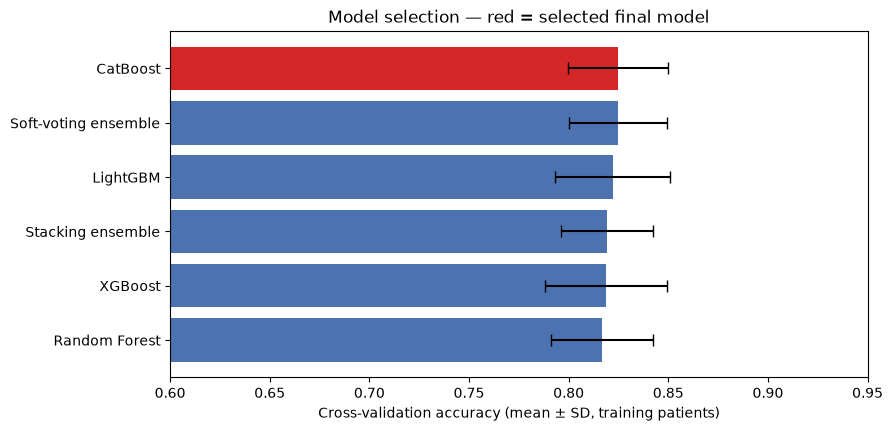

In [56]:
members = [(n.replace(" ", "_"), m) for n, m in tuned.items()]
candidates = dict(tuned)
candidates["Soft-voting ensemble"] = VotingClassifier(members, voting="soft", n_jobs=1)
candidates["Stacking ensemble"] = StackingClassifier(members, final_estimator=LogisticRegression(max_iter=3000),
                                                     cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=1)

# Repeated CV (5 folds x 3 repeats) on training patients gives a stable score for every candidate
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_table = []
for name, model in candidates.items():
    t0 = time.time()
    s = cross_validate(clone(model), X_tr, y_tr, cv=RCV, n_jobs=-1,
                       scoring={"acc": "accuracy", "f1": "f1_macro", "bal": "balanced_accuracy"})
    cv_table.append({"Model": name, "CV accuracy": s["test_acc"].mean(), "CV acc SD": s["test_acc"].std(),
                     "CV macro F1": s["test_f1"].mean(), "CV balanced acc": s["test_bal"].mean()})
    print(f"{name:22s} accuracy {s['test_acc'].mean():.4f} ± {s['test_acc'].std():.4f} ({time.time() - t0:.0f}s)")

cv_table = pd.DataFrame(cv_table).sort_values("CV accuracy", ascending=False).reset_index(drop=True)
FINAL_NAME = cv_table.loc[0, "Model"]
print("\nSelected final model (best CV accuracy):", FINAL_NAME)
display(cv_table.round(4))

plt.figure(figsize=(9, 4.5))
plt.barh(cv_table["Model"][::-1], cv_table["CV accuracy"][::-1], xerr=cv_table["CV acc SD"][::-1],
         color=["#d62728" if m == FINAL_NAME else "#4c72b0" for m in cv_table["Model"][::-1]], capsize=4)
plt.xlim(0.6, 0.95)
plt.xlabel("Cross-validation accuracy (mean ± SD, training patients)")
plt.title("Model selection — red = selected final model")
save_fig("01_model_selection_cv_accuracy")


## 10.3 Final evaluation on the locked 156-patient test set (evaluated once)

In [57]:
final_model = clone(candidates[FINAL_NAME]).fit(X_tr, y_tr)
proba_te = final_model.predict_proba(X_te)
pred_te = proba_te.argmax(1)
y_true = y_te.to_numpy()

def full_metrics(y, p, pr):
    return {
        "Accuracy": accuracy_score(y, p),
        "Balanced accuracy": balanced_accuracy_score(y, p),
        "Macro precision": precision_score(y, p, average="macro"),
        "Macro recall": recall_score(y, p, average="macro"),
        "Macro F1": f1_score(y, p, average="macro"),
        "Weighted F1": f1_score(y, p, average="weighted"),
        "Macro ROC-AUC (OvR)": roc_auc_score(y, pr, multi_class="ovr", average="macro"),
        "Appendicitis sensitivity": recall_score(y > 0, p > 0),
        "Appendicitis specificity": recall_score(y > 0, p > 0, pos_label=False),
        "Complicated sensitivity": recall_score(y == 2, p == 2),
        "Complicated specificity": recall_score(y == 2, p == 2, pos_label=False),
    }

final_metrics = full_metrics(y_true, pred_te, proba_te)

# 95% bootstrap confidence intervals (resampling the test patients)
rng = np.random.default_rng(SEED)
boot = {"Accuracy": [], "Macro F1": []}
for _ in range(2000):
    i = rng.integers(0, len(y_true), len(y_true))
    boot["Accuracy"].append(accuracy_score(y_true[i], pred_te[i]))
    boot["Macro F1"].append(f1_score(y_true[i], pred_te[i], average="macro"))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}

print(f"FINAL MODEL: {FINAL_NAME}")
print(f"Test accuracy : {final_metrics['Accuracy']:.4f}  (95% CI {ci['Accuracy'][0]:.3f}–{ci['Accuracy'][1]:.3f})")
print(f"Test macro F1 : {final_metrics['Macro F1']:.4f}  (95% CI {ci['Macro F1'][0]:.3f}–{ci['Macro F1'][1]:.3f})")
display(pd.Series(final_metrics).round(4).to_frame("Test set"))
print(classification_report(y_true, pred_te, target_names=CLASS_NAMES, digits=4))

# Same test patients, every candidate — for reference only (the choice above was made by CV)
ref = []
for name, model in candidates.items():
    m = model if name in tuned else clone(model).fit(X_tr, y_tr)
    pr = (final_model if name == FINAL_NAME else m).predict_proba(X_te)
    ref.append({"Model": name, "Test accuracy": accuracy_score(y_true, pr.argmax(1)),
                "Test macro F1": f1_score(y_true, pr.argmax(1), average="macro"),
                "Complicated recall": recall_score(y_true == 2, pr.argmax(1) == 2),
                "Selected by CV": name == FINAL_NAME})
ref = pd.DataFrame(ref).merge(cv_table[["Model", "CV accuracy"]], on="Model")
display(ref.sort_values("CV accuracy", ascending=False).round(4))
ref.to_csv(os.path.join(RESULTS, "final_model_comparison.csv"), index=False)


FINAL MODEL: CatBoost
Test accuracy : 0.8590  (95% CI 0.801–0.910)
Test macro F1 : 0.8163  (95% CI 0.735–0.882)


,Test set
Accuracy,0.8590
Balanced accuracy,0.8004
Macro precision,0.8435
Macro recall,0.8004
Macro F1,0.8163
Weighted F1,0.8556
Macro ROC-AUC (OvR),0.9396
Appendicitis sensitivity,0.9570
Appendicitis specificity,0.9048
Complicated sensitivity,0.5833


                 precision    recall  f1-score   support

No appendicitis     0.9344    0.9048    0.9194        63
  Uncomplicated     0.8182    0.9130    0.8630        69
    Complicated     0.7778    0.5833    0.6667        24

       accuracy                         0.8590       156
      macro avg     0.8435    0.8004    0.8163       156
   weighted avg     0.8589    0.8590    0.8556       156



,Model,Test accuracy,Test macro F1,Complicated recall,Selected by CV,CV accuracy
2,CatBoost,0.8590,0.8163,0.5833,True,0.8248
4,Soft-voting ensemble,0.8526,0.7889,0.4583,False,0.8248
1,LightGBM,0.8462,0.7767,0.4167,False,0.8221
5,Stacking ensemble,0.8526,0.7918,0.4583,False,0.8194
0,XGBoost,0.8462,0.7876,0.5000,False,0.8189
3,Random Forest,0.8462,0.7926,0.5000,False,0.8168


## 10.4 Graphs

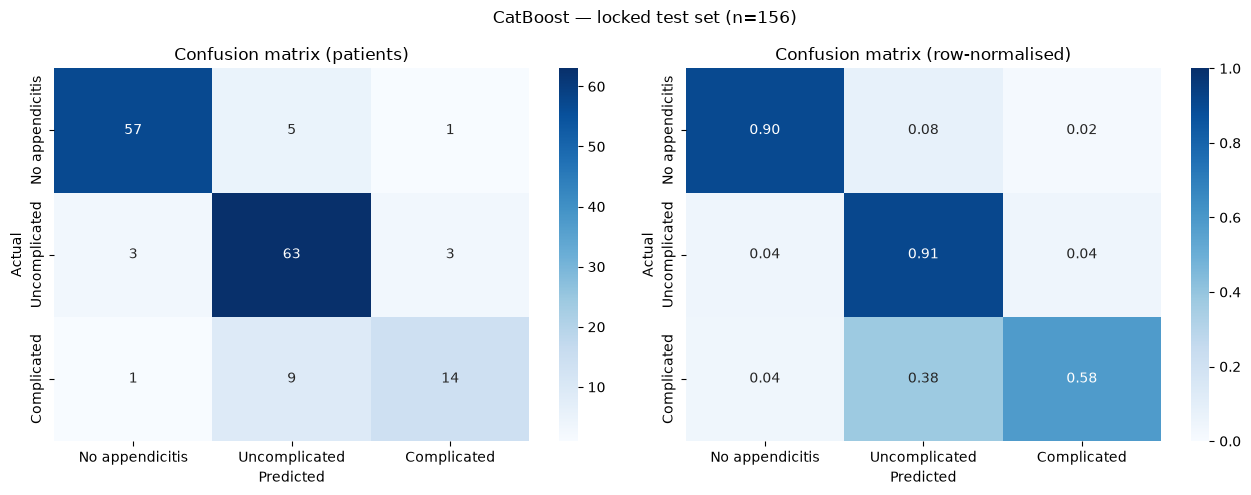

In [58]:
# Confusion matrices: counts and row-normalised (recall per class)
cm = confusion_matrix(y_true, pred_te)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
axes[0].set_title("Confusion matrix (patients)")
axes[1].set_title("Confusion matrix (row-normalised)")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle(f"{FINAL_NAME} — locked test set (n={len(y_true)})")
plt.tight_layout()
save_fig("02_confusion_matrix")


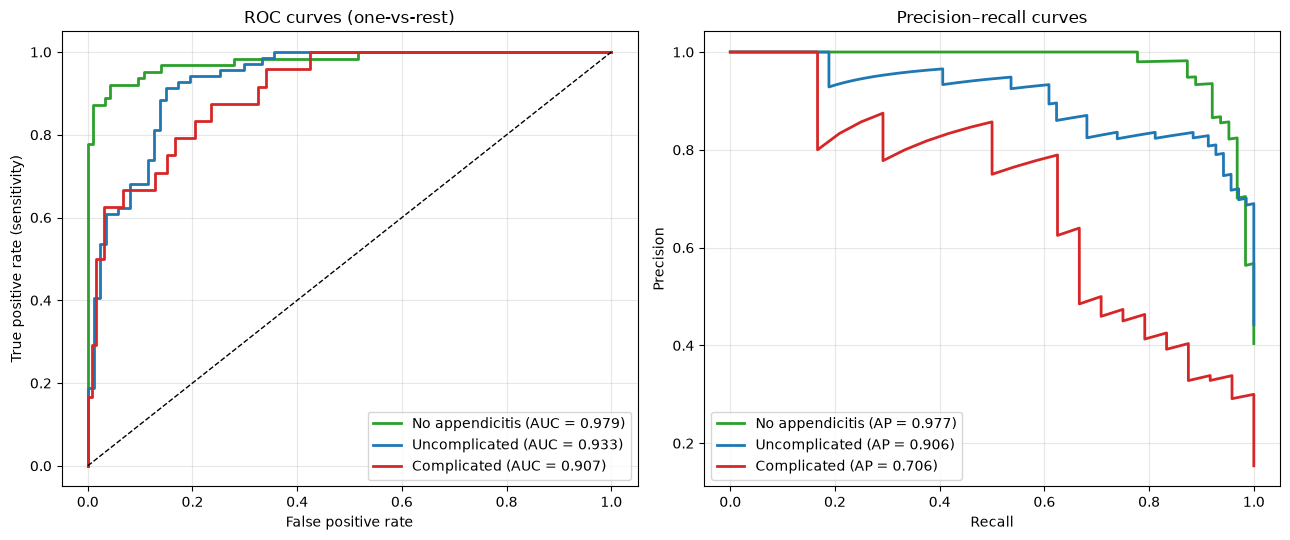

In [59]:
# ROC curves (one-vs-rest) and precision–recall curves
Y = label_binarize(y_true, classes=[0, 1, 2])
colors = ["#2ca02c", "#1f77b4", "#d62728"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for c in range(3):
    fpr, tpr, _ = roc_curve(Y[:, c], proba_te[:, c])
    axes[0].plot(fpr, tpr, color=colors[c], lw=2, label=f"{CLASS_NAMES[c]} (AUC = {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(Y[:, c], proba_te[:, c])
    axes[1].plot(rec, prec, color=colors[c], lw=2,
                 label=f"{CLASS_NAMES[c]} (AP = {average_precision_score(Y[:, c], proba_te[:, c]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (sensitivity)", title="ROC curves (one-vs-rest)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left")
    ax.grid(alpha=0.3)
plt.tight_layout()
save_fig("03_roc_and_pr_curves")


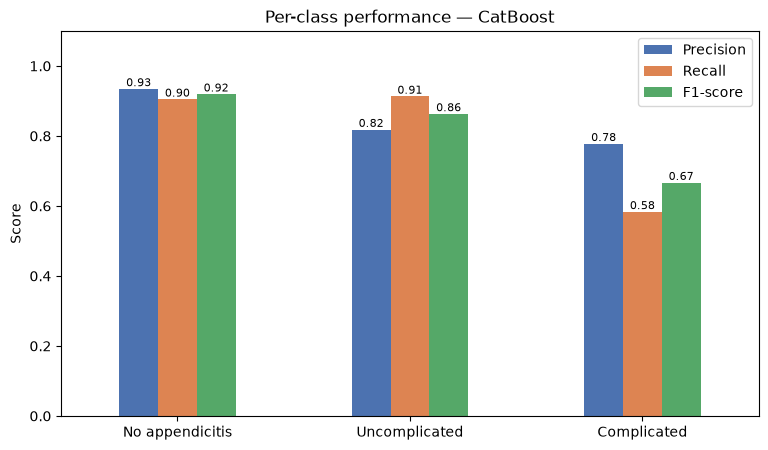

In [60]:
# Per-class precision / recall / F1
rep = classification_report(y_true, pred_te, output_dict=True)
per_class = pd.DataFrame({CLASS_NAMES[c]: [rep[str(c)]["precision"], rep[str(c)]["recall"], rep[str(c)]["f1-score"]]
                          for c in range(3)}, index=["Precision", "Recall", "F1-score"])
ax = per_class.T.plot(kind="bar", figsize=(9, 5), rot=0, color=["#4c72b0", "#dd8452", "#55a868"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.ylim(0, 1.1)
plt.title(f"Per-class performance — {FINAL_NAME}")
plt.ylabel("Score")
save_fig("04_per_class_metrics")


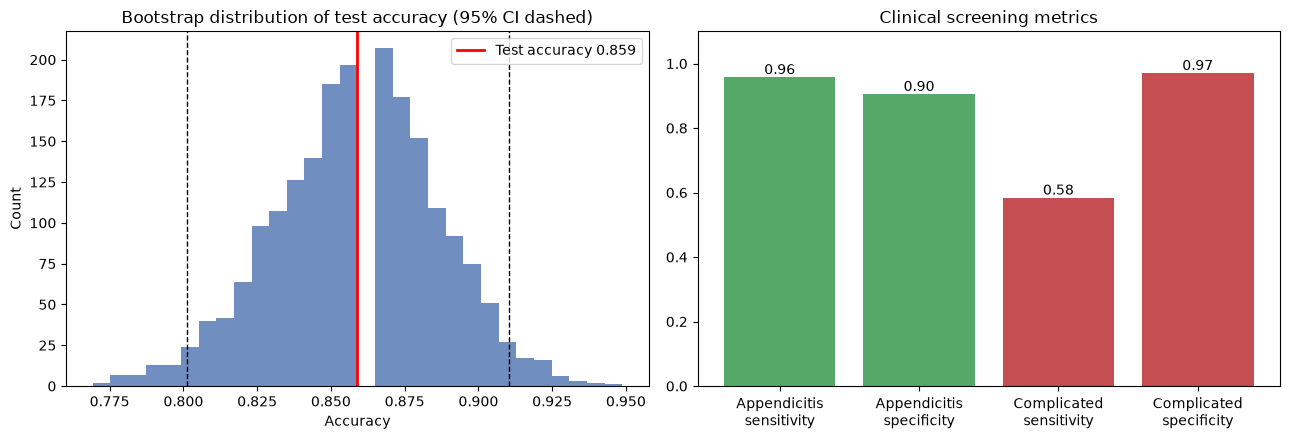

In [61]:
# Accuracy with 95% bootstrap CI, and clinical sensitivity/specificity
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(boot["Accuracy"], bins=30, color="#4c72b0", alpha=0.8)
axes[0].axvline(final_metrics["Accuracy"], color="red", lw=2, label=f"Test accuracy {final_metrics['Accuracy']:.3f}")
for v in ci["Accuracy"]:
    axes[0].axvline(v, color="black", ls="--", lw=1)
axes[0].set(title="Bootstrap distribution of test accuracy (95% CI dashed)", xlabel="Accuracy", ylabel="Count")
axes[0].legend()
clin = pd.Series({k: final_metrics[k] for k in ["Appendicitis sensitivity", "Appendicitis specificity",
                                                  "Complicated sensitivity", "Complicated specificity"]})
bars = axes[1].bar(range(4), clin.values, color=["#55a868", "#55a868", "#c44e52", "#c44e52"])
axes[1].bar_label(bars, fmt="%.2f")
axes[1].set_xticks(range(4), [s.replace(" ", "\n") for s in clin.index])
axes[1].set(ylim=(0, 1.1), title="Clinical screening metrics")
plt.tight_layout()
save_fig("05_accuracy_ci_and_sensitivity")


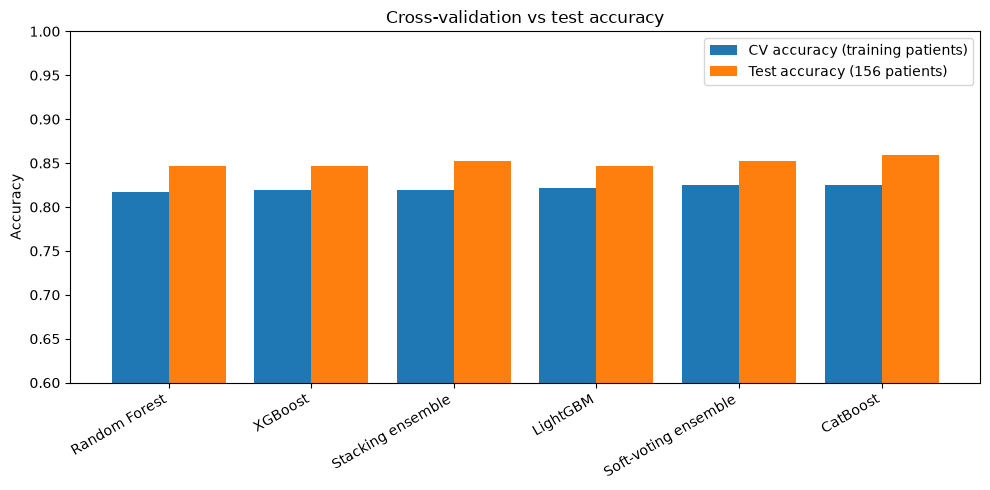

In [62]:
# Cross-validation vs test accuracy for every candidate
plot_df = ref.sort_values("CV accuracy")
x = np.arange(len(plot_df))
plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, plot_df["CV accuracy"], 0.4, label="CV accuracy (training patients)")
plt.bar(x + 0.2, plot_df["Test accuracy"], 0.4, label="Test accuracy (156 patients)")
plt.xticks(x, plot_df["Model"], rotation=30, ha="right")
plt.ylim(0.6, 1.0)
plt.ylabel("Accuracy")
plt.title("Cross-validation vs test accuracy")
plt.legend()
plt.tight_layout()
save_fig("06_cv_vs_test_accuracy")


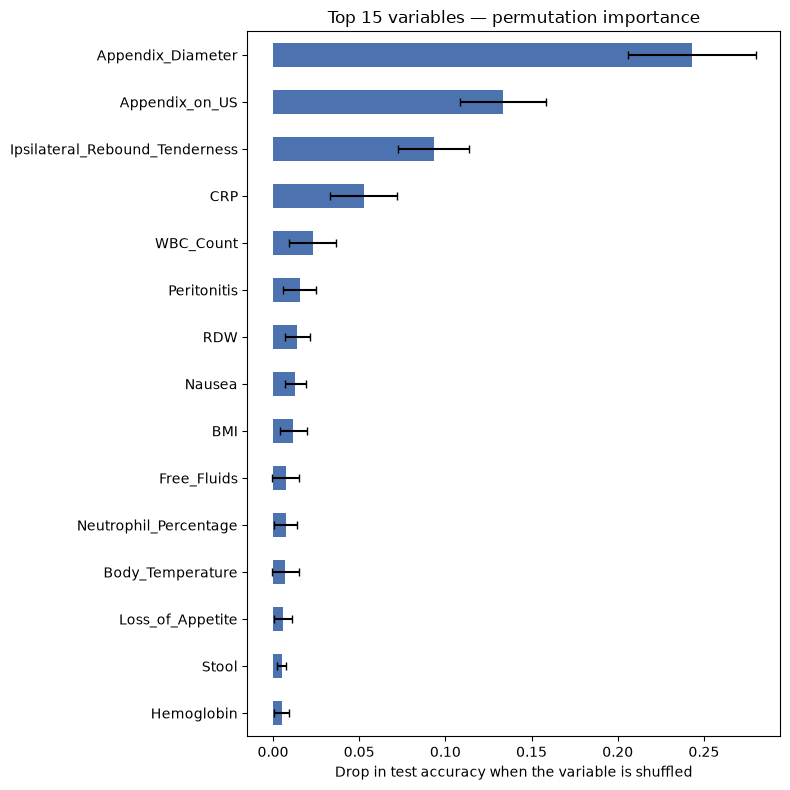

,Accuracy drop
Appendix_Diameter,0.2429
Appendix_on_US,0.1333
Ipsilateral_Rebound_Tenderness,0.0933
CRP,0.0526
WBC_Count,0.0231
Peritonitis,0.0154
RDW,0.0141
Nausea,0.0128
BMI,0.0119
Neutrophil_Percentage,0.0074


In [63]:
# Which patient variables matter most? (permutation importance on the test set, raw input variables)
pi = permutation_importance(final_model, X_te, y_te, scoring="accuracy", n_repeats=20,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(8, 8))
imp.tail(15).plot(kind="barh", xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.tail(15).index],
                  color="#4c72b0", capsize=3)
plt.xlabel("Drop in test accuracy when the variable is shuffled")
plt.title("Top 15 variables — permutation importance")
plt.tight_layout()
save_fig("07_permutation_importance")
display(imp.sort_values(ascending=False).head(15).round(4).to_frame("Accuracy drop"))


## 10.5 Save the model for the web app
The final model is retrained on **all 780 patients** (standard practice once evaluation is finished)
and saved together with everything the app needs to build its input form.

In [64]:
deploy_model = clone(candidates[FINAL_NAME]).fit(X_all, y_all)
joblib.dump(deploy_model, os.path.join(APP_DIR, "appendicitis_model.joblib"))

model_info = {
    "model_name": FINAL_NAME,
    "classes": CLASS_NAMES,
    "features": FEATURES,
    "numeric_features": {c: {"min": float(X_all[c].min()), "max": float(X_all[c].max()),
                             "median": float(X_all[c].median())} for c in NUMERIC},
    "categorical_features": {c: sorted(X_all[c].dropna().astype(str).unique().tolist()) for c in CATEGORICAL},
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "test_accuracy_95ci": [round(float(v), 4) for v in ci["Accuracy"]],
    "cv_accuracy": round(float(cv_table.loc[0, "CV accuracy"]), 4),
    "trained_on_patients": int(len(X_all)),
    "disclaimer": "Research prototype. Not a medical device. Predictions must not replace clinical judgement.",
}
with open(os.path.join(APP_DIR, "model_info.json"), "w") as f:
    json.dump(model_info, f, indent=2)
print("Saved:", os.listdir(APP_DIR))


Saved: ['appendicitis_model.joblib', 'model_info.json']


In [65]:
# How the app will call the model: one patient in, probabilities out (missing values are allowed)
def predict_patient(patient: dict, model_path=os.path.join(APP_DIR, "appendicitis_model.joblib")):
    model = joblib.load(model_path)
    row = pd.DataFrame([{f: patient.get(f, np.nan) for f in FEATURES}])
    row[CATEGORICAL] = row[CATEGORICAL].astype(object)
    probs = model.predict_proba(row)[0]
    return {"prediction": CLASS_NAMES[int(probs.argmax())],
            "probabilities": {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, probs)}}

example = X_te.iloc[0].dropna().to_dict()
print("Example input:", example)
print("Model output :", predict_patient(example))
print("True class   :", CLASS_NAMES[int(y_te.iloc[0])])


Example input: {'Age': 6.76, 'BMI': 15.5, 'Sex': 'female', 'Height': 122.0, 'Weight': 22.9, 'Appendix_on_US': 'yes', 'Appendix_Diameter': 5.0, 'Migratory_Pain': 'yes', 'Lower_Right_Abd_Pain': 'yes', 'Contralateral_Rebound_Tenderness': 'no', 'Coughing_Pain': 'yes', 'Nausea': 'no', 'Loss_of_Appetite': 'no', 'Body_Temperature': 37.4, 'WBC_Count': 19.7, 'Neutrophil_Percentage': 75.5, 'Neutrophilia': 'yes', 'RBC_Count': 4.77, 'Hemoglobin': 13.4, 'RDW': 12.2, 'Thrombocyte_Count': 330.0, 'CRP': 1.0, 'Dysuria': 'no', 'Stool': 'normal', 'Peritonitis': 'no', 'Psoas_Sign': 'no', 'Ipsilateral_Rebound_Tenderness': 'yes', 'US_Performed': 'yes', 'Free_Fluids': 'yes'}
Model output : {'prediction': 'No appendicitis', 'probabilities': {'No appendicitis': 0.9789, 'Uncomplicated': 0.0193, 'Complicated': 0.0018}}
True class   : No appendicitis


# 11. Validation: does ultrasound add value?
Five setups are compared on the **same 578 patients** with 5-fold cross-validation repeated 5 times
(25 train/test rounds). Nothing is tuned on test data.
- **A** clinical only (no ultrasound information)
- **B** clinical + structured ultrasound findings
- **C** ultrasound images only
- **D1** early fusion (B + image features)
- **D2** late fusion (combines B and C predictions)

### Setup

In [66]:
import os, re, time, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, classification_report)
from xgboost import XGBClassifier

import glob

def find_one(pattern, what):
    hits = sorted(glob.glob(pattern, recursive=True))
    if not hits:
        raise FileNotFoundError(f"Could not find {what} ({pattern}). Attach it via 'Add Input'.")
    return hits[0]

if os.path.exists("/kaggle/input"):
    # Kaggle: find files under any attached dataset
    DATA_XLSX = find_one("/kaggle/input/**/app_data.xlsx", "app_data.xlsx")
    IMG_DIR = os.path.dirname(find_one("/kaggle/input/**/US_Pictures/**/*.bmp", "US_Pictures images"))
    WEIGHTS = find_one("/kaggle/input/**/resnet18*.pth", "ResNet18 weights")
    RESULTS = "/kaggle/working/results"
else:
    # Local laptop
    PROJECT = r"C:\Users\MUSAIB\Desktop\Appendixai"
    DATA_XLSX = os.path.join(PROJECT, "Data", "clinical", "app_data.xlsx")
    IMG_DIR = os.path.join(PROJECT, "Data", "ultrasound", "US_Pictures")
    WEIGHTS = os.path.join(PROJECT, "models", "resnet18-f37072fd (1).pth")
    RESULTS = os.path.join(PROJECT, "results")
os.makedirs(RESULTS, exist_ok=True)
print("Data   :", DATA_XLSX)
print("Images :", IMG_DIR)
print("Weights:", WEIGHTS)
print("Results:", RESULTS)

SEED = 42
np.random.seed(SEED)
CLASS_NAMES = ["No appendicitis", "Uncomplicated", "Complicated"]


Data   : C:\Users\MUSAIB\Desktop\Appendixai\Data\clinical\app_data.xlsx
Images : C:\Users\MUSAIB\Desktop\Appendixai\Data\ultrasound\US_Pictures
Weights: C:\Users\MUSAIB\Desktop\Appendixai\models\resnet18-f37072fd (1).pth
Results: C:\Users\MUSAIB\Desktop\Appendixai\results


### Load data, clean, build target (same rules as the Kaggle notebook)

In [67]:
df = pd.read_excel(DATA_XLSX)
df = df.drop(index=[428, 535])          # Diagnosis/Severity missing
df.loc[625, "Sex"] = "male"             # single missing Sex value (same fix as before)

def create_target(row):
    if row["Diagnosis"] == "no appendicitis":
        return 0
    if row["Diagnosis"] == "appendicitis" and row["Severity"] == "uncomplicated":
        return 1
    if row["Diagnosis"] == "appendicitis" and row["Severity"] == "complicated":
        return 2
    return np.nan

df["Target"] = df.apply(create_target, axis=1)
df = df.dropna(subset=["Target"]).copy()
df["Target"] = df["Target"].astype(int)

# Feature groups (listed by name: pandas 3 stores text as "str", so select_dtypes is unsafe)
US_FINDINGS = ["Appendix_on_US", "Appendix_Diameter", "US_Performed", "Free_Fluids"]
CLINICAL_ONLY = ["Age", "BMI", "Sex", "Height", "Weight",
                 "Migratory_Pain", "Lower_Right_Abd_Pain", "Contralateral_Rebound_Tenderness",
                 "Coughing_Pain", "Nausea", "Loss_of_Appetite", "Body_Temperature",
                 "WBC_Count", "Neutrophil_Percentage", "Neutrophilia", "RBC_Count",
                 "Hemoglobin", "RDW", "Thrombocyte_Count", "Ketones_in_Urine",
                 "RBC_in_Urine", "WBC_in_Urine", "CRP", "Dysuria", "Stool",
                 "Peritonitis", "Psoas_Sign", "Ipsilateral_Rebound_Tenderness"]
TABULAR = CLINICAL_ONLY[:5] + ["Appendix_on_US", "Appendix_Diameter"] + CLINICAL_ONLY[5:] + ["US_Performed", "Free_Fluids"]
NUMERIC = ["Age", "BMI", "Height", "Weight", "Appendix_Diameter", "Body_Temperature",
           "WBC_Count", "Neutrophil_Percentage", "RBC_Count", "Hemoglobin", "RDW",
           "Thrombocyte_Count", "CRP"]

print("Patients:", len(df))
print("Target counts:", df["Target"].value_counts().sort_index().to_dict())
print("Clinical-only features:", len(CLINICAL_ONLY), "| Tabular (clinical + US findings):", len(TABULAR))


Patients: 780
Target counts: {0: 317, 1: 345, 2: 118}
Clinical-only features: 28 | Tabular (clinical + US findings): 32


### Link ultrasound images to patients, save the cohort

In [68]:
records = []
for f in sorted(os.listdir(IMG_DIR)):
    m = re.match(r"^(\d+)\.", f)
    if m and f.lower().endswith((".bmp", ".png", ".jpg", ".jpeg")):
        records.append({"filename": f, "us_number": int(m.group(1))})
img_df = pd.DataFrame(records)

df["us_number"] = df["US_Number"].astype("Int64")
paired_ids = sorted(set(img_df["us_number"]) & set(df["us_number"].dropna().astype(int)))
img_df = img_df[img_df["us_number"].isin(paired_ids)].reset_index(drop=True)

cohort = df[df["us_number"].isin(paired_ids)].copy()
cohort["n_images"] = cohort["us_number"].map(img_df["us_number"].value_counts())
cohort[["us_number", "Target", "n_images"]].to_csv(os.path.join(RESULTS, "cohort.csv"), index=False)

print("Paired patients:", len(cohort), "| images:", len(img_df))
print("Paired target counts:", cohort["Target"].value_counts().sort_index().to_dict())


Paired patients: 578 | images: 1721
Paired target counts: {0: 196, 1: 286, 2: 96}


### Helpers: preprocessing + metrics

In [69]:
def make_preprocessor(features):
    num = [c for c in features if c in NUMERIC]
    cat = [c for c in features if c not in NUMERIC]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])

def make_xgb():
    # Same settings as the tuned XGBoost in the Kaggle notebook (cell 293)
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.03, min_child_weight=5,
                         objective="multi:softprob", eval_metric="mlogloss",
                         tree_method="hist", random_state=SEED, n_jobs=-1)

def compute_metrics(y_true, proba):
    y_pred = proba.argmax(1)
    appy_true, appy_pred = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "f1_no_app": f1_score(y_true, y_pred, labels=[0], average="macro"),
        "f1_uncomp": f1_score(y_true, y_pred, labels=[1], average="macro"),
        "f1_comp": f1_score(y_true, y_pred, labels=[2], average="macro"),
        "recall_comp": recall_score(y_true, y_pred, labels=[2], average="macro"),
        "precision_comp": precision_score(y_true, y_pred, labels=[2], average="macro", zero_division=0),
        "auc_macro_ovr": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
        "appendicitis_sensitivity": recall_score(appy_true, appy_pred),
        "appendicitis_specificity": recall_score(appy_true, appy_pred, pos_label=0),
    }


### Reproduce the original clinical XGBoost (624/156 split, all 780 patients)

In [70]:
X_tr, X_te, y_tr, y_te = train_test_split(df[TABULAR], df["Target"], test_size=0.20,
                                          random_state=SEED, stratify=df["Target"])
repro = Pipeline([("prep", make_preprocessor(TABULAR)), ("clf", make_xgb())])
repro.fit(X_tr, y_tr)
proba = repro.predict_proba(X_te)
print("Train/test:", X_tr.shape, X_te.shape)
print("Accuracy:", round(accuracy_score(y_te, proba.argmax(1)), 4), " (Kaggle notebook reported 0.859)")
print(confusion_matrix(y_te, proba.argmax(1)))
print(classification_report(y_te, proba.argmax(1), target_names=CLASS_NAMES, digits=3))


Train/test: (624, 32) (156, 32)
Accuracy: 0.8718  (Kaggle notebook reported 0.859)
[[57  5  1]
 [ 2 66  1]
 [ 1 10 13]]
                 precision    recall  f1-score   support

No appendicitis      0.950     0.905     0.927        63
  Uncomplicated      0.815     0.957     0.880        69
    Complicated      0.867     0.542     0.667        24

       accuracy                          0.872       156
      macro avg      0.877     0.801     0.824       156
   weighted avg      0.877     0.872     0.866       156



### Fixed patient-level CV splits on the paired cohort (5 folds x 5 repeats), saved

In [71]:
y_all = cohort["Target"].to_numpy()
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
SPLITS = list(rskf.split(np.zeros(len(y_all)), y_all))

split_rows = []
for k, (_, te) in enumerate(SPLITS):
    for i in te:
        split_rows.append({"us_number": int(cohort["us_number"].iloc[i]), "repeat": k // 5, "fold": k % 5})
pd.DataFrame(split_rows).to_csv(os.path.join(RESULTS, "splits.csv"), index=False)
print("Folds:", len(SPLITS), "| saved results/splits.csv")


Folds: 25 | saved results/splits.csv


### Extract frozen ResNet18 features (once), mean+max per patient, cached to disk

In [72]:
import torch, torch.nn as nn
from torchvision import models, transforms
from PIL import Image

EMB_PATH = os.path.join(RESULTS, "resnet18_patient_meanmax.npy")
if os.path.exists(EMB_PATH):
    US_FEATS = np.load(EMB_PATH)
    print("Loaded cached image features:", US_FEATS.shape)
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    net = models.resnet18(weights=None)
    net.load_state_dict(torch.load(WEIGHTS, map_location="cpu"))
    net.fc = nn.Identity()
    net = net.to(device).eval()

    tf = transforms.Compose([transforms.ToTensor(),
                             transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    def load(path, size=224):
        img = Image.open(path).convert("RGB")
        img.thumbnail((size, size), Image.Resampling.LANCZOS)      # keep aspect ratio
        canvas = Image.new("RGB", (size, size), (0, 0, 0))
        canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
        return tf(canvas)

    feats = []
    t0 = time.time()
    with torch.no_grad():
        for s in range(0, len(img_df), 32):
            batch = torch.stack([load(os.path.join(IMG_DIR, f)) for f in img_df["filename"].iloc[s:s + 32]])
            feats.append(net(batch.to(device)).cpu().numpy())
    feats = np.concatenate(feats)
    print("Image features:", feats.shape, f"in {time.time() - t0:.0f}s on {device}")

    US_FEATS = np.stack([
        np.concatenate([feats[img_df["us_number"].to_numpy() == pid].mean(0),
                        feats[img_df["us_number"].to_numpy() == pid].max(0)])
        for pid in cohort["us_number"].astype(int)
    ])
    np.save(EMB_PATH, US_FEATS)
    print("Patient image features:", US_FEATS.shape, "| saved", EMB_PATH)


Loaded cached image features: (578, 1024)


### Run all models on the SAME folds

In [73]:
#  A  clinical only (XGBoost)
#  B  clinical + structured US findings (XGBoost)
#  C  ultrasound images only (scaler -> PCA 32 -> logistic regression)
#  D1 early fusion: B features + 16 PCA image components (XGBoost)
#  D2 late fusion: stacks out-of-fold probabilities of B and C (logistic regression)
def image_model():
    return Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=32, random_state=SEED)),
                     ("lr", LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000))])

def fit_predict_B(Xtr, ytr, Xte):
    m = Pipeline([("prep", make_preprocessor(TABULAR)), ("clf", make_xgb())]).fit(Xtr, ytr)
    return m.predict_proba(Xte)

def fit_predict_C(Utr, ytr, Ute):
    return image_model().fit(Utr, ytr).predict_proba(Ute)

Xc = cohort[TABULAR].reset_index(drop=True)
rows, oof = [], {}
t0 = time.time()
for k, (tr, te) in enumerate(SPLITS):
    ytr, yte = y_all[tr], y_all[te]
    preds = {}

    preds["A_clinical_only"] = Pipeline([("prep", make_preprocessor(CLINICAL_ONLY)), ("clf", make_xgb())]) \
        .fit(Xc.iloc[tr][CLINICAL_ONLY], ytr).predict_proba(Xc.iloc[te][CLINICAL_ONLY])
    preds["B_clinical+US_findings"] = fit_predict_B(Xc.iloc[tr], ytr, Xc.iloc[te])
    preds["C_US_images_only"] = fit_predict_C(US_FEATS[tr], ytr, US_FEATS[te])

    # D1 early fusion (preprocessor and PCA fitted on the training fold only)
    prep = make_preprocessor(TABULAR).fit(Xc.iloc[tr])
    sc = StandardScaler().fit(US_FEATS[tr])
    pca = PCA(n_components=16, random_state=SEED).fit(sc.transform(US_FEATS[tr]))
    Ztr = np.hstack([prep.transform(Xc.iloc[tr]), pca.transform(sc.transform(US_FEATS[tr]))])
    Zte = np.hstack([prep.transform(Xc.iloc[te]), pca.transform(sc.transform(US_FEATS[te]))])
    preds["D1_early_fusion"] = make_xgb().fit(Ztr, ytr).predict_proba(Zte)

    # D2 late fusion: inner 5-fold out-of-fold probabilities train the stacker (no test data used)
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    meta_X = np.zeros((len(tr), 6))
    for itr, ite in inner.split(np.zeros(len(tr)), ytr):
        meta_X[ite, :3] = fit_predict_B(Xc.iloc[tr[itr]], ytr[itr], Xc.iloc[tr[ite]])
        meta_X[ite, 3:] = fit_predict_C(US_FEATS[tr[itr]], ytr[itr], US_FEATS[tr[ite]])
    stacker = LogisticRegression(max_iter=3000).fit(meta_X, ytr)
    preds["D2_late_fusion"] = stacker.predict_proba(np.hstack([preds["B_clinical+US_findings"],
                                                               preds["C_US_images_only"]]))

    for name, p in preds.items():
        rows.append({"model": name, "repeat": k // 5, "fold": k % 5, **compute_metrics(yte, p)})
        if k < 5:   # first repeat covers every patient once -> confusion matrices
            oof.setdefault(name, np.zeros((len(y_all), 3)))[te] = p
    print(f"fold {k + 1}/{len(SPLITS)} done ({time.time() - t0:.0f}s)")

results = pd.DataFrame(rows)
results.to_csv(os.path.join(RESULTS, "cv_results_per_fold.csv"), index=False)


fold 1/25 done (5s)


fold 2/25 done (10s)


fold 3/25 done (16s)


fold 4/25 done (21s)


fold 5/25 done (26s)


fold 6/25 done (31s)


... (15 outputs left out)

fold 22/25 done (113s)


fold 23/25 done (118s)


fold 24/25 done (123s)


fold 25/25 done (128s)


### Summary table (mean ± SD over 25 folds) + confusion matrices

In [74]:
metrics = ["accuracy", "macro_f1", "weighted_f1", "f1_comp", "recall_comp", "auc_macro_ovr",
           "appendicitis_sensitivity", "appendicitis_specificity"]
summary = results.groupby("model")[metrics].agg(["mean", "std"])
table = pd.DataFrame({m: summary[m]["mean"].map("{:.3f}".format) + " ± " + summary[m]["std"].map("{:.3f}".format)
                      for m in metrics})
table.to_csv(os.path.join(RESULTS, "cv_summary.csv"))
pd.set_option("display.width", 250)
print(table.to_string())

for name, p in oof.items():
    print(f"\n{name} — confusion matrix (repeat 1, all {len(y_all)} patients):")
    print(confusion_matrix(y_all, p.argmax(1)))


                             accuracy       macro_f1    weighted_f1        f1_comp    recall_comp  auc_macro_ovr appendicitis_sensitivity appendicitis_specificity
model                                                                                                                                                             
A_clinical_only         0.644 ± 0.040  0.629 ± 0.048  0.642 ± 0.041  0.582 ± 0.095  0.535 ± 0.122  0.812 ± 0.030            0.834 ± 0.033            0.627 ± 0.060
B_clinical+US_findings  0.822 ± 0.027  0.773 ± 0.034  0.817 ± 0.027  0.573 ± 0.078  0.518 ± 0.103  0.935 ± 0.016            0.956 ± 0.025            0.902 ± 0.040
C_US_images_only        0.563 ± 0.040  0.543 ± 0.039  0.569 ± 0.041  0.424 ± 0.065  0.554 ± 0.092  0.741 ± 0.033            0.784 ± 0.052            0.652 ± 0.081
D1_early_fusion         0.811 ± 0.034  0.756 ± 0.052  0.804 ± 0.038  0.546 ± 0.121  0.483 ± 0.145  0.930 ± 0.017            0.947 ± 0.024            0.885 ± 0.034
D2_late_fusion        

### Does adding images help? Paired comparison on identical folds

In [75]:
def paired(a, b, metric):
    ra = results[results.model == a].sort_values(["repeat", "fold"])[metric].to_numpy()
    rb = results[results.model == b].sort_values(["repeat", "fold"])[metric].to_numpy()
    d = rb - ra
    print(f"{b} vs {a} [{metric}]: mean diff {d.mean():+.3f}, {int((d > 0).sum())}/{len(d)} folds better")

for metric in ["accuracy", "macro_f1", "recall_comp"]:
    paired("A_clinical_only", "B_clinical+US_findings", metric)
    paired("B_clinical+US_findings", "D1_early_fusion", metric)
    paired("B_clinical+US_findings", "D2_late_fusion", metric)


B_clinical+US_findings vs A_clinical_only [accuracy]: mean diff +0.178, 25/25 folds better
D1_early_fusion vs B_clinical+US_findings [accuracy]: mean diff -0.011, 6/25 folds better
D2_late_fusion vs B_clinical+US_findings [accuracy]: mean diff +0.001, 11/25 folds better
B_clinical+US_findings vs A_clinical_only [macro_f1]: mean diff +0.144, 25/25 folds better
D1_early_fusion vs B_clinical+US_findings [macro_f1]: mean diff -0.017, 10/25 folds better
D2_late_fusion vs B_clinical+US_findings [macro_f1]: mean diff -0.004, 12/25 folds better
B_clinical+US_findings vs A_clinical_only [recall_comp]: mean diff -0.017, 8/25 folds better
D1_early_fusion vs B_clinical+US_findings [recall_comp]: mean diff -0.035, 5/25 folds better
D2_late_fusion vs B_clinical+US_findings [recall_comp]: mean diff -0.037, 3/25 folds better


### Validation chart

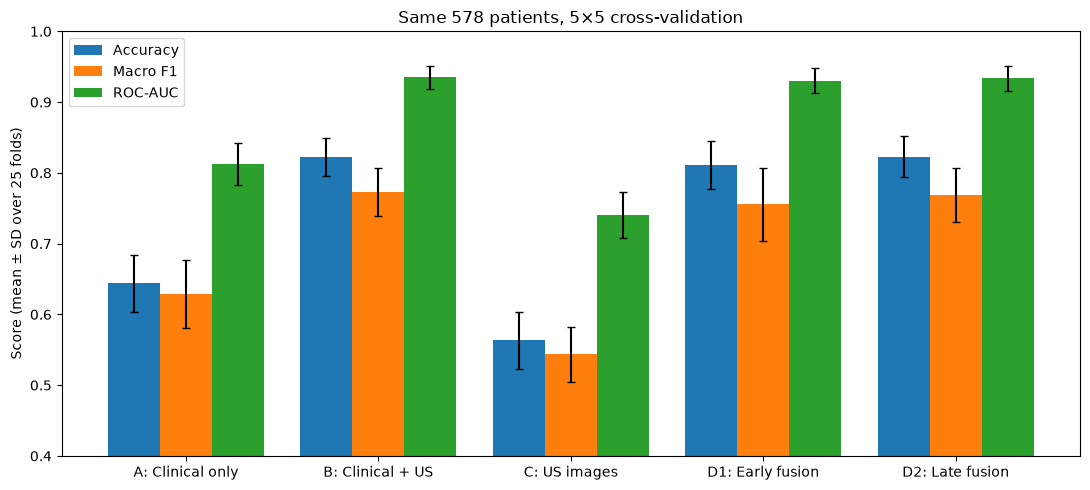

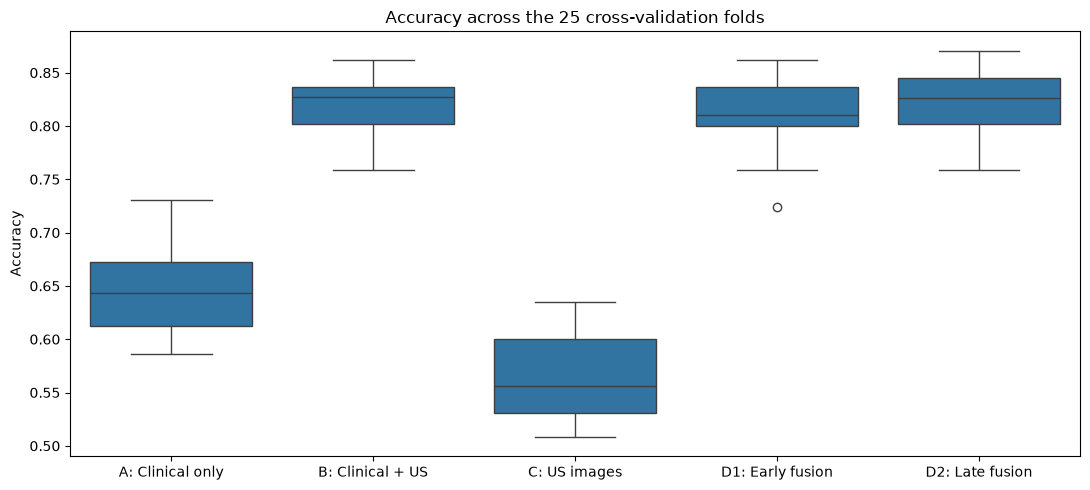

In [76]:
order = ["A_clinical_only", "B_clinical+US_findings", "C_US_images_only", "D1_early_fusion", "D2_late_fusion"]
labels = ["A: Clinical only", "B: Clinical + US", "C: US images", "D1: Early fusion", "D2: Late fusion"]
means = results.groupby("model")[["accuracy", "macro_f1", "auc_macro_ovr"]].mean().loc[order]
sds = results.groupby("model")[["accuracy", "macro_f1", "auc_macro_ovr"]].std().loc[order]
x = np.arange(len(order))
plt.figure(figsize=(11, 5))
for j, (col, name) in enumerate([("accuracy", "Accuracy"), ("macro_f1", "Macro F1"), ("auc_macro_ovr", "ROC-AUC")]):
    plt.bar(x + (j - 1) * 0.27, means[col], 0.27, yerr=sds[col], capsize=3, label=name)
plt.xticks(x, labels)
plt.ylim(0.4, 1.0)
plt.ylabel("Score (mean ± SD over 25 folds)")
plt.title("Same 578 patients, 5×5 cross-validation")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "figures_final_model", "08_validation_five_setups.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(11, 5))
sns.boxplot(data=results, x="model", y="accuracy", order=order)
plt.xticks(range(5), labels)
plt.title("Accuracy across the 25 cross-validation folds")
plt.ylabel("Accuracy")
plt.xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "figures_final_model", "09_validation_boxplot.png"), dpi=300, bbox_inches="tight")
plt.show()


# 12. Conclusion

**Final model.** A tuned CatBoost model on 32 clinical, laboratory and structured ultrasound variables,
chosen by cross-validation and tested once on 156 locked patients (see Section 10 for the exact numbers).

**What drives the prediction.** Appendix diameter, whether the appendix is seen on ultrasound,
rebound tenderness, CRP and white-cell count.

**Does ultrasound help?** Structured ultrasound findings help a lot (setup A → B). Raw ultrasound images,
represented with a pretrained ResNet18, did not add measurable accuracy on top of them (B ≈ D1 ≈ D2).

**Hardest task.** Telling complicated from uncomplicated appendicitis: complicated cases are the
smallest class and are most often confused with uncomplicated cases.

**Limitations.** Single centre, retrospective data, 780 patients (578 with images), no external validation.
"Complicated" is the dataset's severity label and is not the same as "perforated".
This is a research prototype, not a medical device.

**Product.** The saved model (`results/app_model/`) powers the web app in the `app/` folder.